# BTS — Análisis consolidado de modelos (Etapa C) y consumo Gold

Este cuaderno **conserva las evaluaciones de la etapa C**: tablas de umbrales y costos, curvas ROC/PR, matrices de confusión, bootstrap pareado, ranking, priorización top-k, calibración, importancia de variables y análisis por subgrupos, además de la comparación opcional con los resultados locales. No reentrena, no recalcula Silver y no modifica las muestras.

**Referencia oficial de esta etapa:** LightGBM y XGBoost usan las predicciones y modelos **float64**; regresión logística y K-means conservan sus checkpoints originales. El análisis principal ya no incorpora la comparación de precisiones numéricas. La elección de LightGBM para tuning responde al equilibrio entre PR-AUC y costo observado de entrenamiento, **no a que haya obtenido el mayor PR-AUC**.

El archivo `veredicto.json` reproduce la regla descriptiva histórica basada en prueba (no debe utilizarse para elegir qué desplegar); `veredicto_validacion.json` identifica el mejor PR-AUC de validación y `decision_candidato_tuning.json` documenta por qué se optimizará LightGBM.

**Destinos oficiales, sustituyendo los outputs anteriores de la etapa C:**
- Local: `../outputs/outputs_modeling/comparison_aws/`
- S3: `s3://bts-flights-analysis/modeling/outputs_modeling/comparison_aws_seed42_h240/`

**Orden:** 1) ejecutar la **Parte I** y publicar sus outputs; 2) ejecutar la **Parte II (Gold)** únicamente cuando el tuning y Gold definitivos hayan terminado.


## Parte I — Etapa C: comparación completa de los cuatro modelos

### 0. Dependencias y rutas (ejecutar desde `SageMaker/src/`)

In [1]:
%pip install -q numpy pandas scikit-learn matplotlib pyarrow boto3 lightgbm


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [20]:
from pathlib import Path
import json, os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    roc_curve, precision_recall_curve, confusion_matrix)

ROOT = Path.cwd()
assert ROOT.name == "src", f"Ejecuta desde SageMaker/src; actual: {ROOT}"

BUCKET = "bts-flights-analysis"
S3_OUTPUT_PREFIX = "modeling/outputs_modeling/comparison_aws_seed42_h240"
ORIGINAL_OUTPUT = Path("../outputs/outputs_modeling")
CHECKPOINTS = ORIGINAL_OUTPUT / "checkpoints"
OUT_DIR = ORIGINAL_OUTPUT / "comparison_aws"
FIG_DIR = OUT_DIR / "figures"
# La salida anterior se reemplazará DESPUÉS de confirmar que los ocho NPZ son legibles.
# Este cambio no modifica ni borra checkpoints de entrenamiento.
REEMPLAZAR_OUTPUTS_ANTERIORES = True

# Opcional: coloca aquí los CSV del antiguo notebook local, SIN sobrescribir los AWS.
LOCAL_REFERENCE = Path("../data/local_reference/outputs_modeling")

COST_FP, COST_FN = 1, 3
T_COMMON = COST_FP / (COST_FP + COST_FN)
SEED = 42
BOOT_ROWS, BOOT_N = 300_000, 100
EXPECTED_EVAL_ROWS = 1_000_000

# Usamos los checkpoints oficiales de esta comparación: LightGBM y XGBoost float64.
CONFIG = {
    "Regresión logística": ("logreg", "logistic-regression-original-seed42-h240"),
    "LightGBM": ("lightgbm_float64", "lightgbm-float64-original-seed42-h240"),
    "XGBoost": ("xgboost_float64", "xgboost-float64-original-seed42-h240"),
    "K-means (tasa por clúster)": ("kmeans", "kmeans-original-seed42-h240"),
}
CONTEST = list(CONFIG)
SELECTED_FOR_TUNING = "LightGBM"

# Tiempos cronometrados en la misma instancia SageMaker por el equipo;
# XGBoost suele incluir training_seconds en run_config.json.
OBSERVED_TRAIN_SECONDS = {"LightGBM": 716.6, "XGBoost": 2516.6}

SIMPLICITY = ["Regresión logística", "K-means (tasa por clúster)", "LightGBM", "XGBoost"]

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()
    plt.close()

print("Destino local:", OUT_DIR.resolve())

Destino local: /home/ec2-user/SageMaker/outputs/outputs_modeling/comparison_aws


## 1. Verificar/recuperar checkpoints (solo predicciones; no descarga modelos grandes)

In [3]:
import boto3

required = ["val_predictions.npz", "test_predictions.npz"]
missing = []
for name, (folder, prefix) in CONFIG.items():
    dest = CHECKPOINTS / folder
    dest.mkdir(parents=True, exist_ok=True)
    for fn in required:
        if not (dest / fn).exists():
            missing.append((name, dest / fn, f"modeling/checkpoints/{prefix}/{fn}"))

if missing:
    session = boto3.Session(region_name="us-east-1")
    if session.get_credentials() is None:
        raise RuntimeError("Faltan checkpoints locales y credenciales AWS. Reinicia el Learner Lab antes de descargar.")
    s3 = session.client("s3")
    for name, target, key in missing:
        print(f"Descargando {name}: {target.name}")
        s3.download_file(BUCKET, key, str(target))
else:
    print("✔ Los 8 archivos NPZ ya están locales. No se descargó nada de S3.")

for name, (folder, _) in CONFIG.items():
    for fn in required:
        assert (CHECKPOINTS / folder / fn).exists(), f"Falta {name} / {fn}"
print("✔ Listo para comparar, sin reentrenamiento.")

✔ Los 8 archivos NPZ ya están locales. No se descargó nada de S3.
✔ Listo para comparar, sin reentrenamiento.


## 2. Leer las predicciones y comprobar alineación exacta de etiquetas

In [4]:
results = {}
y_by_split = {}
for model_name, (folder, _) in CONFIG.items():
    results[model_name] = {}
    for split in ("val", "test"):
        path = CHECKPOINTS / folder / f"{split}_predictions.npz"
        with np.load(path) as z:
            assert set(("y", "p")).issubset(set(z.files)), f"{path}: no tiene y, p"
            y = np.asarray(z["y"], dtype=np.uint8)
            p = np.asarray(z["p"], dtype=np.float64)
        assert y.ndim == p.ndim == 1 and len(y) == len(p) == EXPECTED_EVAL_ROWS, (
            f"{model_name}/{split}: tamaños inesperados {y.shape}, {p.shape}")
        assert np.all(np.isfinite(p)) and np.all((0 <= p) & (p <= 1)), f"Probabilidades inválidas: {model_name}/{split}"
        if split in y_by_split:
            assert np.array_equal(y_by_split[split], y), f"No coinciden etiquetas de {model_name}/{split}: no comparar"
        else:
            y_by_split[split] = y
        results[model_name][split] = p

y_val = y_by_split["val"]
y_test = y_by_split["test"]
print(f"✔ Etiquetas de los cuatro modelos alineadas: validación={len(y_val):,}, prueba={len(y_test):,}")
print(f"Prevalencia validación={y_val.mean():.3%} | prueba={y_test.mean():.3%}")
print("RAM aproximada de arreglos (GiB):", round((sum(p.nbytes for d in results.values() for p in d.values()) + y_val.nbytes + y_test.nbytes) / 1024**3, 3))
# Solo si los NPZ de todos los modelos pasaron las comprobaciones,
# reemplazar el directorio local de outputs anteriores (nunca los checkpoints).
if REEMPLAZAR_OUTPUTS_ANTERIORES and OUT_DIR.exists():
    import shutil
    assert OUT_DIR.resolve() == (ORIGINAL_OUTPUT / "comparison_aws").resolve(), "Directorio de salida inesperado"
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("✔ Destino del análisis preparado; resultados anteriores de etapa C reemplazados localmente.")


✔ Etiquetas de los cuatro modelos alineadas: validación=1,000,000, prueba=1,000,000
Prevalencia validación=22.270% | prueba=22.927%
RAM aproximada de arreglos (GiB): 0.061
✔ Destino del análisis preparado; resultados anteriores de etapa C reemplazados localmente.


## 3. Comparación original: tablas de métricas, umbrales y presupuesto de alertas

In [5]:
sys.path.insert(0, str(Path("utils").resolve()))
import model_eval as me

thr_cost = {n: me.best_cost_threshold(y_val, data["val"], c_fp=COST_FP, c_fn=COST_FN)
            for n, data in results.items()}
tab_thr = pd.DataFrame([
    me.evaluate_model(n, y_test, results[n]["test"], thr_cost[n], c_fp=COST_FP, c_fn=COST_FN)
    for n in CONTEST
]).set_index("modelo")
tab_common = pd.DataFrame([
    me.evaluate_model(n, y_test, results[n]["test"], T_COMMON, c_fp=COST_FP, c_fn=COST_FN)
    for n in CONTEST
]).set_index("modelo")

# Replica alert_budget_table() original con estabilidad en los empates.
budget_rows = []
for n in CONTEST:
    ys = y_test[np.argsort(-results[n]["test"], kind="stable")]
    row = {"modelo": n}
    for k in (0.05, 0.10, 0.20):
        m = int(len(ys) * k)
        row[f"precisión top {k:.0%}"] = float(ys[:m].mean())
        row[f"recall top {k:.0%}"] = float(ys[:m].sum() / ys.sum())
    budget_rows.append(row)
tab_budget = pd.DataFrame(budget_rows).set_index("modelo")

prev_test = float(y_test.mean())
print("PR-AUC azar (prevalencia en prueba):", round(prev_test, 5))
print("Costo / 1000 — nunca alertar:", round(COST_FN * prev_test * 1000, 2), "| alertar siempre:", round(COST_FP * (1 - prev_test) * 1000, 2))
print("A) Métricas independientes del umbral")
display(tab_thr[["roc_auc", "pr_auc", "brier", "log_loss", "ece"]].sort_values("pr_auc", ascending=False))
print("B) Umbrales por costo obtenidos exclusivamente en validación")
display(tab_thr[["umbral", "precision", "recall", "f1", "alertas_%", "costo_x1000"]])
print("C) Mismo presupuesto de alertas")
display(tab_budget)

tab_thr.to_csv(OUT_DIR / "comparison_threshold_cost.csv")
tab_common.to_csv(OUT_DIR / "comparison_threshold_common.csv")
tab_budget.to_csv(OUT_DIR / "comparison_alert_budget.csv")
pd.concat([
    tab_thr.assign(umbral_tipo="costo (validación)"),
    tab_common.assign(umbral_tipo="común teórico")
]).to_csv(OUT_DIR / "model_comparison_full.csv")
print("✔ Guardados: 4 CSV de comparación original.")

PR-AUC azar (prevalencia en prueba): 0.22927
Costo / 1000 — nunca alertar: 687.8 | alertar siempre: 770.73
A) Métricas independientes del umbral


,roc_auc,pr_auc,brier,log_loss,ece
modelo,,,,,
XGBoost,0.761381,0.547231,0.142923,0.449593,0.001859
LightGBM,0.759279,0.544631,0.143378,0.450892,0.002197
Regresión logística,0.734435,0.489063,0.150931,0.470886,0.008773
K-means (tasa por clúster),0.692171,0.418372,0.159978,0.494068,0.011493


B) Umbrales por costo obtenidos exclusivamente en validación


,umbral,precision,recall,f1,alertas_%,costo_x1000
modelo,,,,,,
Regresión logística,0.252789,0.426183,0.572032,0.488452,0.307727,470.936
LightGBM,0.249884,0.446365,0.601251,0.512359,0.308821,445.234
XGBoost,0.257855,0.455355,0.591407,0.514539,0.297768,443.209
K-means (tasa por clúster),0.257609,0.402792,0.473601,0.435336,0.269571,523.048


C) Mismo presupuesto de alertas


,precisión top 5%,recall top 5%,precisión top 10%,recall top 10%,precisión top 20%,recall top 20%
modelo,,,,,,
Regresión logística,0.69290,0.151112,0.60936,0.265786,0.499590,0.435815
LightGBM,0.78346,0.170862,0.66683,0.290853,0.532525,0.464546
XGBoost,0.78500,0.171198,0.67032,0.292375,0.535280,0.466949
K-means (tasa por clúster),0.60204,0.131297,0.52698,0.229854,0.440910,0.384626


✔ Guardados: 4 CSV de comparación original.


## 4. Gráficas originales — curvas ROC/PR y matrices de confusión

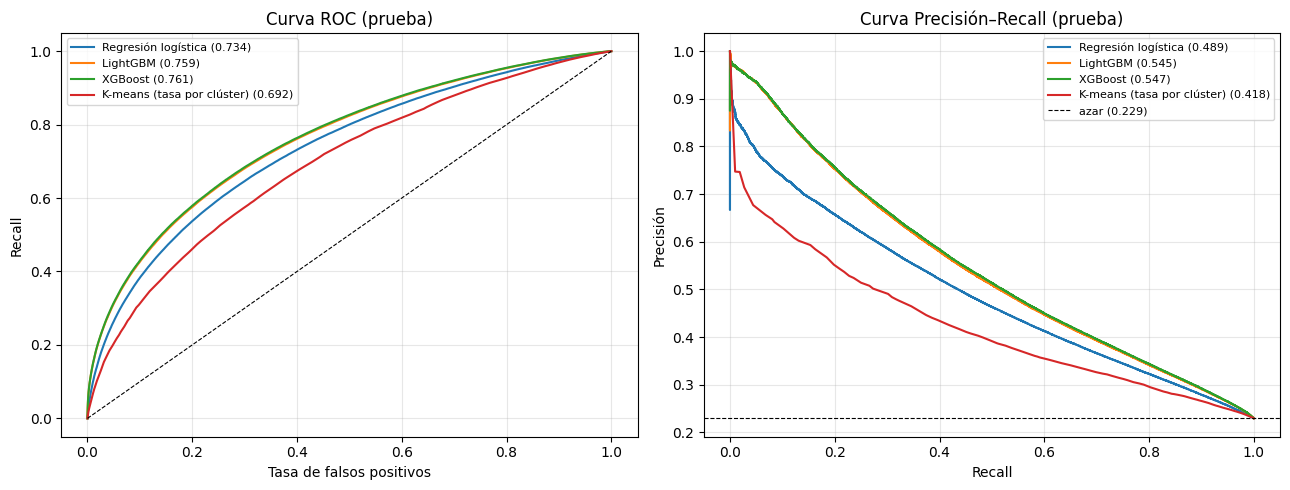

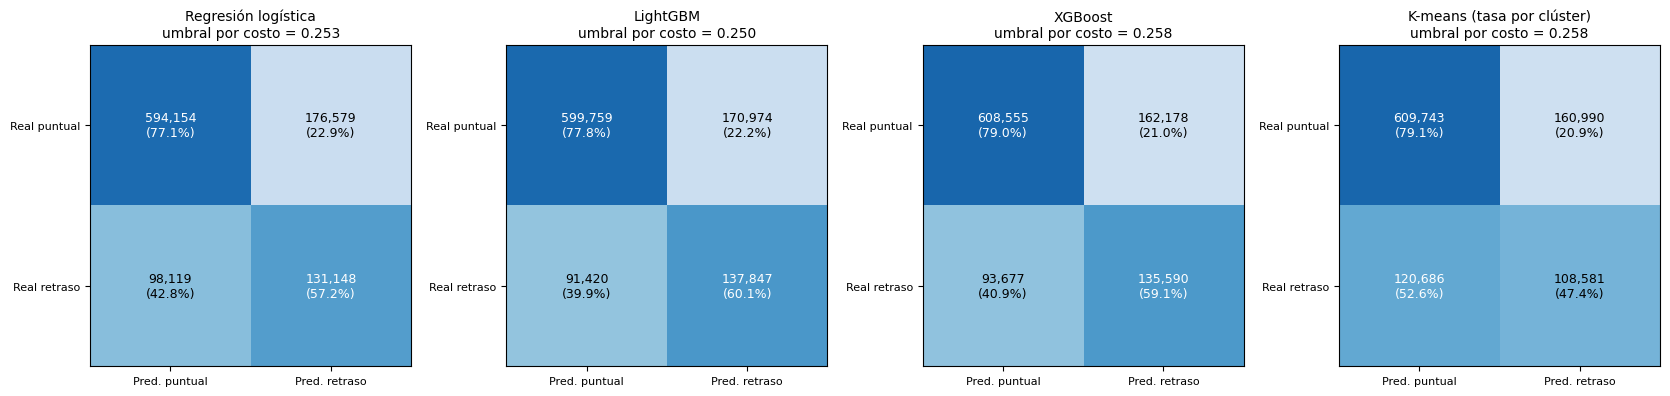

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name in CONTEST:
    p = results[name]["test"]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test,p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y_test,p):.3f})")
ax[0].plot([0,1], [0,1], "k--", lw=.8)
ax[0].set(title="Curva ROC (prueba)", xlabel="Tasa de falsos positivos", ylabel="Recall")
ax[1].axhline(prev_test, color="k", ls="--", lw=.8, label=f"azar ({prev_test:.3f})")
ax[1].set(title="Curva Precisión–Recall (prueba)", xlabel="Recall", ylabel="Precisión")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
save_fig("roc_pr_curves")

fig, axes = plt.subplots(1, len(CONTEST), figsize=(4.2 * len(CONTEST), 4))
for a, name in zip(axes, CONTEST):
    cm = confusion_matrix(y_test, results[name]["test"] >= thr_cost[name], labels=[0,1])
    pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    a.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i,j]:,}\n({pct[i,j]:.1%})", ha="center", va="center",
                   color="white" if pct[i,j]>.5 else "black", fontsize=9)
    a.set_xticks([0,1], ["Pred. puntual", "Pred. retraso"], fontsize=8)
    a.set_yticks([0,1], ["Real puntual", "Real retraso"], fontsize=8)
    a.set_title(f"{name}\numbral por costo = {thr_cost[name]:.3f}", fontsize=10)
save_fig("confusion_matrices")

## 5. Bootstrap pareado original y veredicto descriptivo de prueba

**Puede durar bastante:** 100 remuestreos, 300.000 registros por par. Se guarda una fila tras cada comparación para que puedas comprobar el progreso. Si completas esta celda no hay que repetirla. Este veredicto reproduce el criterio **original** por PR-AUC en prueba, pero no es adecuado para elegir el endpoint.

In [7]:
pr_test = {n: float(average_precision_score(y_test, results[n]["test"])) for n in CONTEST}
pr_val = {n: float(average_precision_score(y_val, results[n]["val"])) for n in CONTEST}
ranking = sorted(CONTEST, key=lambda n: -pr_test[n])
top_test = ranking[0]
rows, tied = [], [top_test]

for other in ranking[1:]:
    print(f"Calculando bootstrap pareado: {top_test} frente a {other} ...")
    d_pr, lo_pr, hi_pr = me.paired_bootstrap_diff(
        y_test, results[top_test]["test"], results[other]["test"], average_precision_score,
        n_boot=BOOT_N, rows=BOOT_ROWS, seed=SEED)
    d_roc, lo_roc, hi_roc = me.paired_bootstrap_diff(
        y_test, results[top_test]["test"], results[other]["test"], roc_auc_score,
        n_boot=BOOT_N, rows=BOOT_ROWS, seed=SEED)
    significant = lo_pr > 0
    if not significant:
        tied.append(other)
    rows.append({"comparación": f"{top_test} − {other}", "Δ PR-AUC": d_pr,
                 "IC95 PR-AUC": f"[{lo_pr:+.4f}, {hi_pr:+.4f}]",
                 "Δ ROC-AUC": d_roc, "IC95 ROC-AUC": f"[{lo_roc:+.4f}, {hi_roc:+.4f}]",
                 "¿supera significativamente?": "sí" if significant else "NO (empate)"})
    pd.DataFrame(rows).to_csv(OUT_DIR / "bootstrap_differences.csv", index=False)
    print("✔ Comparación guardada")

WINNER_ORIGINAL = min(tied, key=SIMPLICITY.index)
rank_table = pd.DataFrame({
    "PR-AUC prueba": pd.Series(pr_test),
    "ROC-AUC prueba": {n: float(roc_auc_score(y_test, results[n]["test"])) for n in CONTEST},
    "Brier prueba": {n: float(brier_score_loss(y_test, results[n]["test"])) for n in CONTEST},
    "PR-AUC validación": pd.Series(pr_val),
}).loc[ranking]
rank_table.to_csv(OUT_DIR / "ranking_modelos.csv")

# Para comparación histórica con notebook local: NO usar este resultado para elegir el despliegue.
verdict_original = {
    "mejor_modelo": WINNER_ORIGINAL,
    "primero_en_pr_auc": top_test,
    "empatados": tied,
    "criterio": "PR-AUC en prueba; bootstrap pareado IC95; parsimonia ante empate",
    "pr_auc_prueba": pr_test,
    "advertencia": "Reconstruye regla histórica sobre test: NO usar para elegir modelo a desplegar",
}
(OUT_DIR / "veredicto.json").write_text(json.dumps(verdict_original, indent=2, ensure_ascii=False))
print("✔ Veredicto de comparación original (solo descriptivo):", WINNER_ORIGINAL)
display(rank_table)
display(pd.DataFrame(rows))

Calculando bootstrap pareado: XGBoost frente a LightGBM ...
✔ Comparación guardada
Calculando bootstrap pareado: XGBoost frente a Regresión logística ...
✔ Comparación guardada
Calculando bootstrap pareado: XGBoost frente a K-means (tasa por clúster) ...
✔ Comparación guardada
✔ Veredicto de comparación original (solo descriptivo): XGBoost


,PR-AUC prueba,ROC-AUC prueba,Brier prueba,PR-AUC validación
XGBoost,0.547231,0.761381,0.142923,0.531467
LightGBM,0.544631,0.759279,0.143378,0.528347
Regresión logística,0.489063,0.734435,0.150931,0.470753
K-means (tasa por clúster),0.418372,0.692171,0.159978,0.398294


,comparación,Δ PR-AUC,IC95 PR-AUC,Δ ROC-AUC,IC95 ROC-AUC,¿supera significativamente?
0,XGBoost − LightGBM,0.002457,"[+0.0019, +0.0030]",0.002160,"[+0.0018, +0.0025]",sí
1,XGBoost − Regresión logística,0.058971,"[+0.0563, +0.0615]",0.026903,"[+0.0256, +0.0285]",sí
2,XGBoost − K-means (tasa por clúster),0.130465,"[+0.1278, +0.1328]",0.068952,"[+0.0672, +0.0704]",sí


## 6. Selección para despliegue basada SOLO en validación

A diferencia del veredicto histórico, éste no consulta prueba para decidir qué candidato recomendar. No sustituye el tuning posterior.

In [8]:
WINNER_VALIDATION = max(pr_val, key=pr_val.get)
validation_table = pd.DataFrame({
    "pr_auc_val": pd.Series(pr_val),
    "roc_auc_val": {n: float(roc_auc_score(y_val, results[n]["val"])) for n in CONTEST},
    "brier_val": {n: float(brier_score_loss(y_val, results[n]["val"])) for n in CONTEST},
    "umbral_costo_val": thr_cost,
}).sort_values("pr_auc_val", ascending=False)
validation_table.to_csv(OUT_DIR / "seleccion_validacion.csv")
verdict_val = {
    "candidato_segun_validacion": WINNER_VALIDATION,
    "criterio": "Máximo PR-AUC en validación (sin consultar prueba)",
    "pr_auc_validacion": pr_val,
    "nota": "La selección definitiva puede cambiar tras tuning y verificaciones posteriores",
}
(OUT_DIR / "veredicto_validacion.json").write_text(json.dumps(verdict_val, indent=2, ensure_ascii=False))
print("✔ Candidato por validación:", WINNER_VALIDATION)
display(validation_table)

✔ Candidato por validación: XGBoost


,pr_auc_val,roc_auc_val,brier_val,umbral_costo_val
XGBoost,0.531467,0.754638,0.141764,0.257855
LightGBM,0.528347,0.752496,0.142244,0.249884
Regresión logística,0.470753,0.729395,0.149428,0.252789
K-means (tasa por clúster),0.398294,0.682811,0.158357,0.257609


## 6A. Comparación adicional: calidad predictiva frente a tiempo de entrenamiento

La tabla original anterior **sigue mostrando a XGBoost como líder de PR-AUC en validación**. Esta sección añade el análisis ingenieril del tiempo de entrenamiento para justificar **por qué LightGBM es el candidato para Optuna**. Las predicciones de LightGBM y XGBoost utilizan float64. Los tiempos proceden de las mediciones del equipo sobre SageMaker (`LightGBM: 716,6 s` y `XGBoost: 2.516,6 s`), con preferencia por los tiempos registrados en los `run_config.json` cuando existan. **Tiempo de entrenamiento ≠ latencia de inferencia.**

,pr_auc_val,roc_auc_val,brier_val,tiempo_entrenamiento_s,arboles,fuente_tiempo
LightGBM,0.528347,0.752496,0.142244,716.60,930,registro del equipo (consola SageMaker)
XGBoost,0.531467,0.754638,0.141764,2516.62,1803,run_config.json


XGBoost supera a LightGBM en PR-AUC validación por: +0.003120
XGBoost tarda 3.51× el tiempo de LightGBM (corridas observadas).


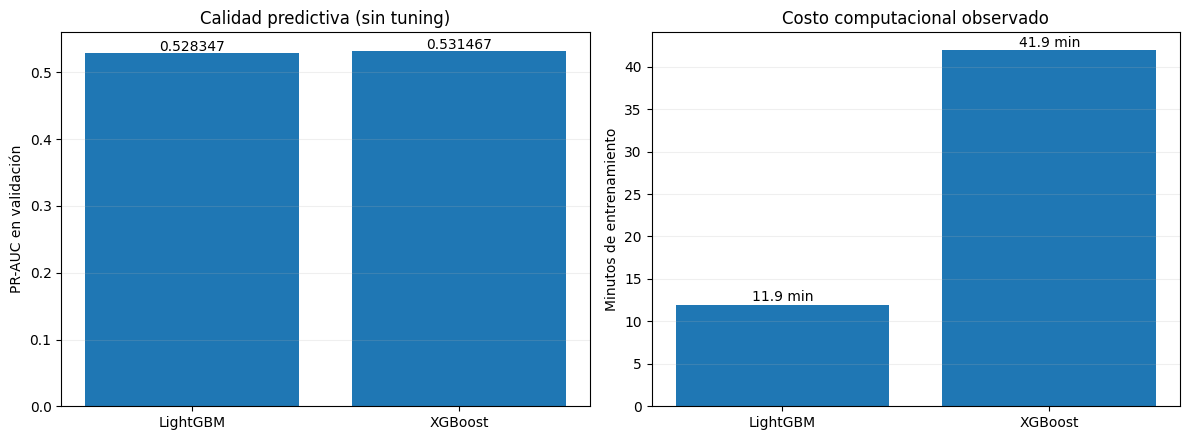

In [9]:
from IPython.display import display

observed_train_seconds = dict(OBSERVED_TRAIN_SECONDS)
expected_iters = {"LightGBM": 930, "XGBoost": 1803}
provenance = {}
for name in ("LightGBM", "XGBoost"):
    folder, prefix = CONFIG[name]
    config_path = CHECKPOINTS / folder / "run_config.json"
    if not config_path.exists():
        session = __import__("boto3").Session(region_name="us-east-1")
        if session.get_credentials() is not None:
            session.client("s3").download_file(BUCKET, f"modeling/checkpoints/{prefix}/run_config.json", str(config_path))
    cfg_run = json.loads(config_path.read_text()) if config_path.exists() else {}
    sec = cfg_run.get("training_seconds")
    if sec is not None:
        observed_train_seconds[name] = float(sec)
        provenance[name] = "run_config.json"
    else:
        provenance[name] = "registro del equipo (consola SageMaker)"
    expected_iters[name] = int(cfg_run.get("best_iteration", expected_iters[name]))

quality_time = validation_table.loc[["LightGBM", "XGBoost"], ["pr_auc_val", "roc_auc_val", "brier_val"]].copy()
quality_time["tiempo_entrenamiento_s"] = pd.Series(observed_train_seconds)
quality_time["arboles"] = pd.Series(expected_iters)
quality_time["fuente_tiempo"] = pd.Series(provenance)
quality_time.to_csv(OUT_DIR / "calidad_vs_costo_entrenamiento.csv")
display(quality_time)

delta_pr = float(quality_time.loc["XGBoost", "pr_auc_val"] - quality_time.loc["LightGBM", "pr_auc_val"])
ratio_time = observed_train_seconds["XGBoost"] / observed_train_seconds["LightGBM"]
print(f"XGBoost supera a LightGBM en PR-AUC validación por: {delta_pr:+.6f}")
print(f"XGBoost tarda {ratio_time:.2f}× el tiempo de LightGBM (corridas observadas).")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
names = list(quality_time.index)
ax[0].bar(names, quality_time["pr_auc_val"])
ax[0].set(title="Calidad predictiva (sin tuning)", ylabel="PR-AUC en validación", ylim=(0, max(.56, quality_time["pr_auc_val"].max()+.02)))
for i,v in enumerate(quality_time["pr_auc_val"]): ax[0].text(i, v+.004, f"{v:.6f}", ha="center")
ax[1].bar(names, quality_time["tiempo_entrenamiento_s"] / 60)
ax[1].set(title="Costo computacional observado", ylabel="Minutos de entrenamiento")
for i,v in enumerate(quality_time["tiempo_entrenamiento_s"] / 60): ax[1].text(i, v+.4, f"{v:.1f} min", ha="center")
for a in ax:
    a.grid(axis="y", alpha=.2)
save_fig("calidad_vs_tiempo")


### 6B. Decisión de ingeniería: qué modelo optimizar

**Resultado predictivo:** el mayor PR-AUC de validación entre los modelos originales corresponde a **XGBoost**. No ocultamos ese dato ni modificamos `veredicto_validacion.json`. **Decisión operativa:** elegimos **LightGBM para el tuning**, dado que obtuvo un desempeño cercano con un tiempo de entrenamiento sustancialmente menor en las corridas observadas. Esta decisión no asegura que LightGBM sea el mejor modelo tras Optuna ni el endpoint definitivo. El resultado se verificará frente al checkpoint XGBoost antes del despliegue.

Este argumento **no** atribuye el cambio local/AWS exclusivamente al hardware ni supone que LightGBM prediga más rápido: esa latencia debe medirse aparte.

In [10]:
selection_record = {
    "etapa": "seleccion_de_candidato_para_optuna",
    "origen": "Etapa C - checkpoints AWS, seed42, horizon240; LightGBM y XGBoost con float64",
    "mejor_pr_auc_validacion_sin_tuning": WINNER_VALIDATION,
    "candidato_para_tuning": SELECTED_FOR_TUNING,
    "modelo_final_endpoint": None,
    "criterio": "Equilibrio entre PR-AUC en validacion y tiempo observado de entrenamiento",
    "pr_auc_validacion": {name: float(pr_val[name]) for name in CONTEST},
    "tiempos_entrenamiento_s": observed_train_seconds,
    "fuente_tiempos": provenance,
    "arboles_observados": expected_iters,
    "diferencia_pr_auc_xgboost_menos_lightgbm": delta_pr,
    "factor_tiempo_xgboost_versus_lightgbm": ratio_time,
    "aclaracion": "XGBoost lidera PR-AUC sin tuning. LightGBM solo se elige para la optimizacion; el despliegue esta pendiente.",
}
(OUT_DIR / "decision_candidato_tuning.json").write_text(json.dumps(selection_record, indent=2, ensure_ascii=False), encoding="utf-8")
print("✔ Decisión documentada sin alterar veredictos originales:", OUT_DIR / "decision_candidato_tuning.json")


✔ Decisión documentada sin alterar veredictos originales: ../outputs/outputs_modeling/comparison_aws/decision_candidato_tuning.json


## 7. Priorización Top-k y calibración del ganador histórico (para comparabilidad con el original)

,top_k_%,vuelos,precision,lift,recall_capturado
0,0.01,10000,0.942000,4.108747,0.041087
1,0.05,50000,0.785000,3.423955,0.171198
2,0.10,100000,0.670320,2.923753,0.292375
3,0.20,200000,0.535280,2.334745,0.466949
4,0.30,300000,0.453917,1.979860,0.593958


,sin calibrar,isotónica
brier,0.142923,0.142950
log_loss,0.449593,0.449715
ece,0.001859,0.004121


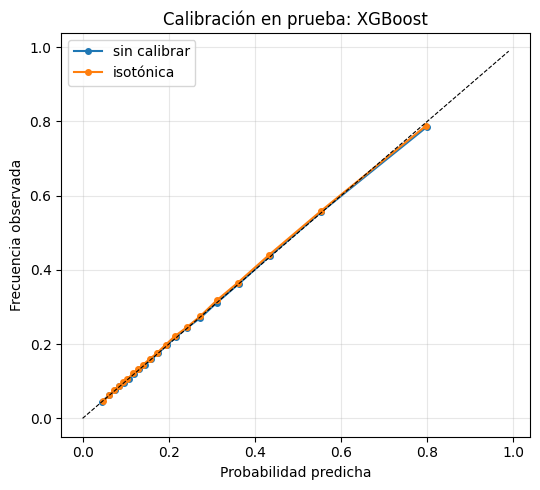

In [11]:
from sklearn.isotonic import IsotonicRegression
p_raw = results[WINNER_ORIGINAL]["test"]
p_val = results[WINNER_ORIGINAL]["val"]

tk = me.top_k_table(y_test, p_raw)
tk.to_csv(OUT_DIR / "top_k_priorizacion.csv", index=False)
display(tk)

iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_val, y_val)
p_cal = iso.predict(p_raw)
calib = pd.DataFrame({
    "sin calibrar": [brier_score_loss(y_test, p_raw), log_loss(y_test, np.clip(p_raw, 1e-6, 1-1e-6)), me.expected_calibration_error(y_test, p_raw)],
    "isotónica": [brier_score_loss(y_test, p_cal), log_loss(y_test, np.clip(p_cal, 1e-6, 1-1e-6)), me.expected_calibration_error(y_test, p_cal)],
}, index=["brier", "log_loss", "ece"])
calib.to_csv(OUT_DIR / "calibration_comparison.csv")
display(calib)

fig, ax = plt.subplots(figsize=(5.5,5))
for label, p in [("sin calibrar", p_raw), ("isotónica", p_cal)]:
    df = pd.DataFrame({"y":y_test, "p":p})
    df["bin"] = pd.qcut(df.p, 20, duplicates="drop")
    g = df.groupby("bin", observed=True).agg(pred=("p", "mean"), obs=("y", "mean"))
    ax.plot(g.pred, g.obs, marker="o", ms=4, label=label)
lim = max(float(p_raw.max()), 0.6)
ax.plot([0,lim],[0,lim],"k--",lw=.8)
ax.set(title=f"Calibración en prueba: {WINNER_ORIGINAL}", xlabel="Probabilidad predicha", ylabel="Frecuencia observada")
ax.legend(); ax.grid(alpha=.3)
save_fig("calibration")

## 8. Importancia de variables del **LightGBM float64** existente (sin reentrenar)

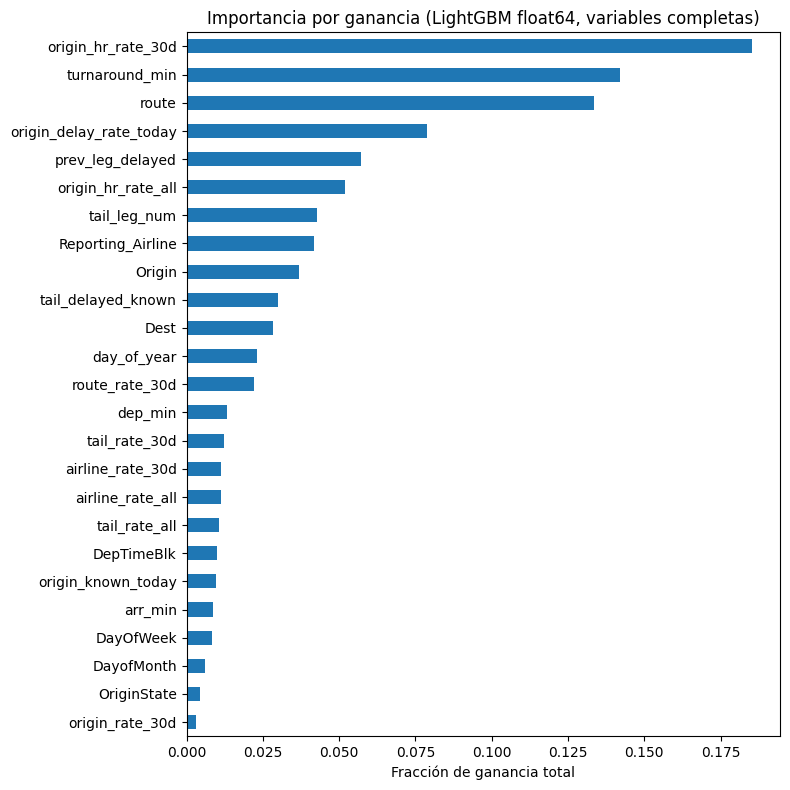

✔ Importancia de variables reconstruida


In [12]:
import lightgbm as lgb
model_file = CHECKPOINTS / "lightgbm_float64" / "model.txt"
if not model_file.exists():
    session = boto3.Session(region_name="us-east-1")
    if session.get_credentials() is None:
        print("Sin credenciales para descargar modelo LightGBM. Omitiendo importancia; no afecta comparación.")
    else:
        model_file.parent.mkdir(parents=True, exist_ok=True)
        session.client("s3").download_file(BUCKET, "modeling/checkpoints/lightgbm-float64-original-seed42-h240/model.txt", str(model_file))

if model_file.exists():
    booster = lgb.Booster(model_file=str(model_file))
    imp = pd.Series(booster.feature_importance("gain"), index=booster.feature_name(), dtype=float)
    if imp.sum() > 0:
        imp = (imp / imp.sum()).sort_values()
        imp.rename("ganancia_relativa").to_csv(OUT_DIR / "feature_importance.csv", header=True)
        fig, ax = plt.subplots(figsize=(8,8))
        imp.tail(25).plot.barh(ax=ax)
        ax.set(title="Importancia por ganancia (LightGBM float64, variables completas)", xlabel="Fracción de ganancia total")
        save_fig("feature_importance")
        print("✔ Importancia de variables reconstruida")
    else:
        print("Modelo sin ganancias registradas; omitiendo gráfico de importancia")
else:
    print("Importancia no disponible; continuará el resto de la comparación")

## 9. Subgrupos de prueba — evaluación histórica del mejor modelo según prueba

Se mantiene **sin modificar** la lógica original de la etapa C: las tablas de subgrupos usan `WINNER_ORIGINAL` para comparación histórica con el notebook previo. Esta sección **no representa** todavía el diagnóstico del LightGBM ajustado final; ese análisis se hará con sus tablas Gold después del tuning.

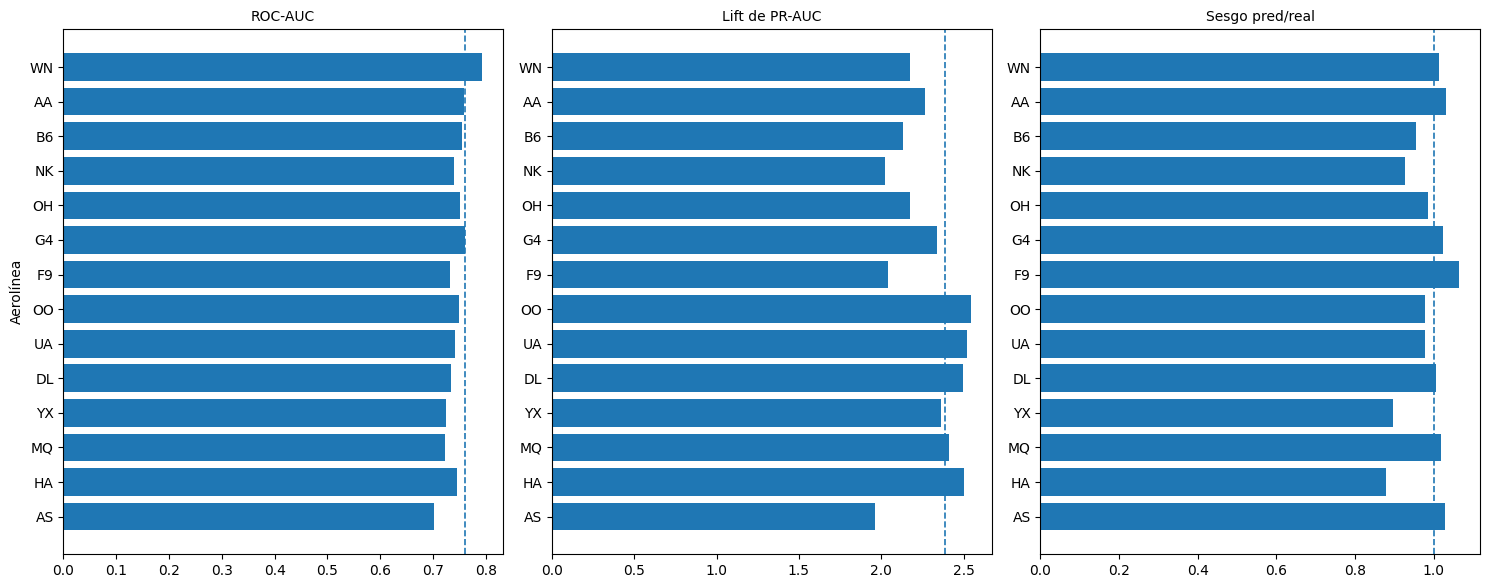

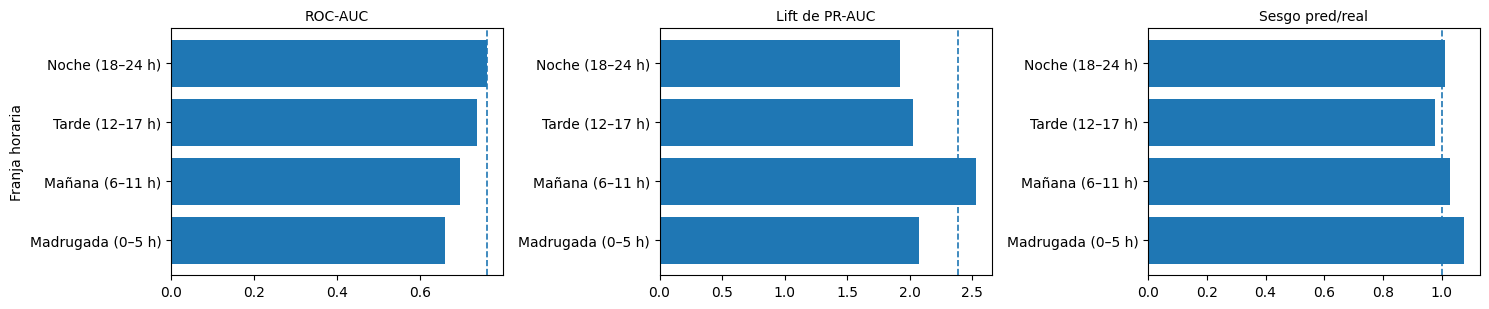

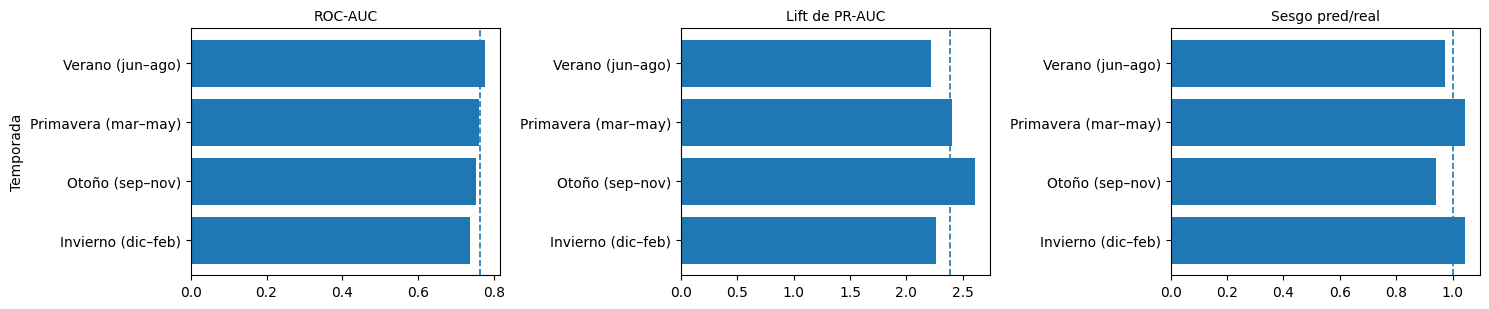

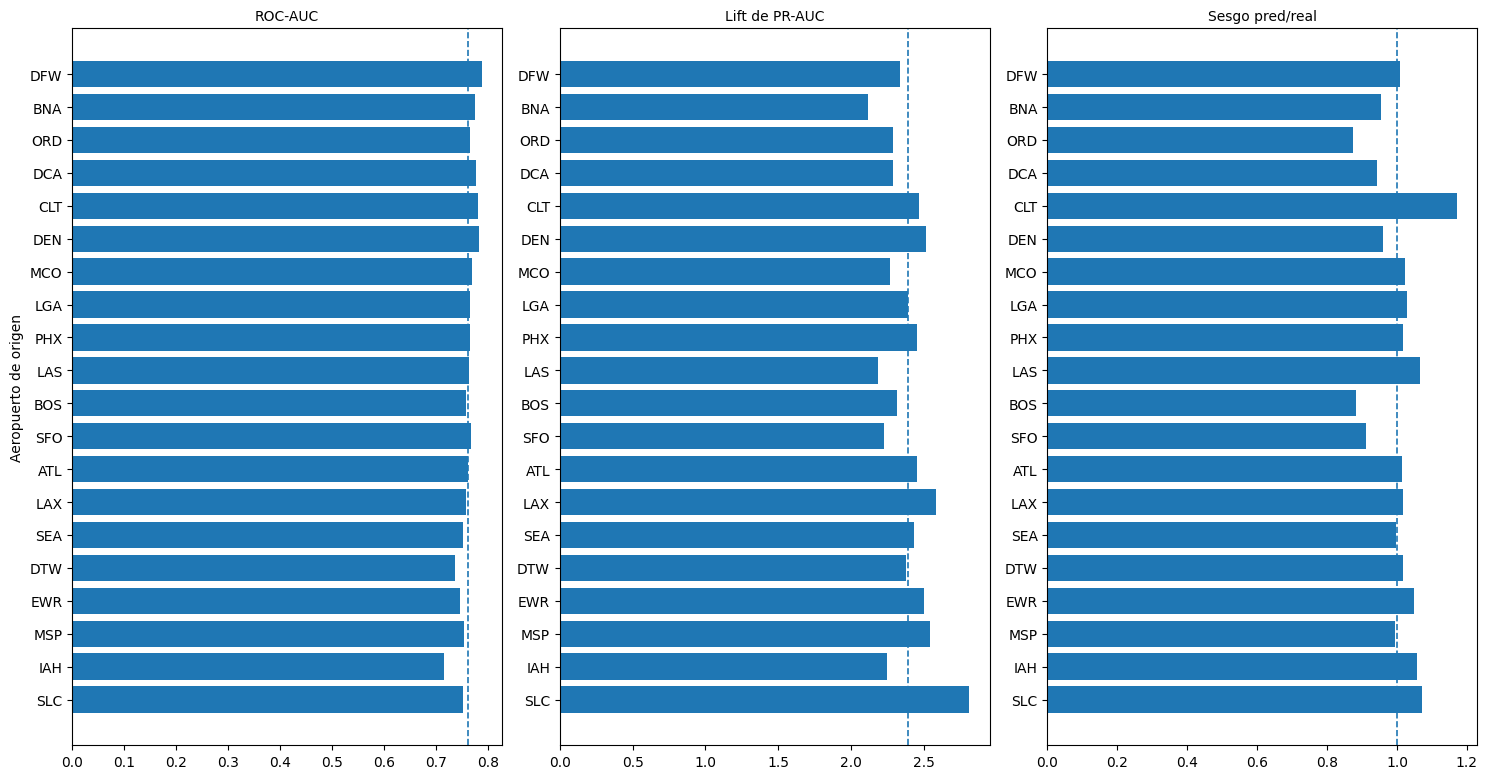

✔ Subgrupos y gráficas guardados


In [13]:
PARTS_BASE = Path("../data/checkpoints/features_seed42_h240_chunk50000")
files = sorted((PARTS_BASE / "test").glob("part_*.parquet"))
needed = ["Reporting_Airline", "Origin", "dep_hour", "Month", "DepDel15"]
if not files:
    print("⚠ No están los Parquet de etapa A en este disco; omitiendo subgrupos (la comparación principal ya quedó guardada)")
else:
    sub = pd.concat([pd.read_parquet(f, columns=needed) for f in files], ignore_index=True)
    assert len(sub) == len(y_test) and np.array_equal(sub.DepDel15.to_numpy(dtype=np.uint8), y_test), "Orden de test no coincide: detener subgrupos"
    sub["y"] = y_test
    sub["p"] = results[WINNER_ORIGINAL]["test"]
    sub["Temporada"] = sub.Month.map(lambda m: "Invierno (dic–feb)" if m in (12,1,2) else "Primavera (mar–may)" if m in (3,4,5) else "Verano (jun–ago)" if m in (6,7,8) else "Otoño (sep–nov)")
    sub["Franja horaria"] = pd.cut(sub.dep_hour, [-1,5,11,17,24], labels=["Madrugada (0–5 h)", "Mañana (6–11 h)", "Tarde (12–17 h)", "Noche (18–24 h)"])
    sub = sub.rename(columns={"Reporting_Airline": "Aerolínea", "Origin": "Aeropuerto de origen"})
    THR = thr_cost[WINNER_ORIGINAL]
    MIN_ROWS = 2000
    def subgroup_metrics(df, by):
        rows=[]
        for key,g in df.groupby(by, observed=True):
            if len(g)<MIN_ROWS or g.y.nunique()<2:continue
            pred = (g.p>=THR).to_numpy()
            gy = g.y.to_numpy()
            tp=int(((pred==1)&(gy==1)).sum()); fp=int(((pred==1)&(gy==0)).sum()); fn=int(((pred==0)&(gy==1)).sum())
            prec=tp/(tp+fp) if tp+fp else 0.
            rec=tp/(tp+fn) if tp+fn else 0.
            rows.append({by:key, "vuelos":len(g), "tasa_real":float(g.y.mean()), "tasa_predicha":float(g.p.mean()),
                         "sesgo (pred/real)":float(g.p.mean()/g.y.mean()), "roc_auc":float(roc_auc_score(gy,g.p)),
                         "pr_auc":float(average_precision_score(gy,g.p)), "lift_pr_auc":float(average_precision_score(gy,g.p)/g.y.mean()),
                         "precision":prec, "recall":rec, "f1":2*prec*rec/(prec+rec) if prec+rec else 0.,
                         "alertas_%":float(pred.mean()), "brier":float(brier_score_loss(gy,g.p))})
        if not rows:return pd.DataFrame()
        return pd.DataFrame(rows).set_index(by)
    overall = {"roc_auc":float(roc_auc_score(y_test,sub.p)), "pr_auc":float(average_precision_score(y_test,sub.p)),
               "lift_pr_auc":float(average_precision_score(y_test,sub.p)/sub.y.mean()),
               "sesgo":float(sub.p.mean()/sub.y.mean())}
    top_ap = sub["Aeropuerto de origen"].value_counts().head(20).index
    groups={
        "Aerolínea":subgroup_metrics(sub,"Aerolínea").sort_values("pr_auc"),
        "Franja horaria":subgroup_metrics(sub,"Franja horaria"),
        "Temporada":subgroup_metrics(sub,"Temporada"),
        "Aeropuerto de origen":subgroup_metrics(sub[sub["Aeropuerto de origen"].isin(top_ap)],"Aeropuerto de origen").sort_values("pr_auc"),
    }
    def shortname(n):return n.lower().replace(" ","_").replace("é","e").replace("ó","o")
    flags=[]
    for name, tab in groups.items():
        if tab.empty: continue
        tab.to_csv(OUT_DIR / f"subgrupos_{shortname(name)}.csv")
        fig, ax = plt.subplots(1,3,figsize=(15,max(3.2,.32*len(tab)+1.5)))
        for a, col, ref, ttl in [(ax[0],"roc_auc",overall["roc_auc"],"ROC-AUC"),
                               (ax[1],"lift_pr_auc",overall["lift_pr_auc"],"Lift de PR-AUC"),
                               (ax[2],"sesgo (pred/real)",overall["sesgo"],"Sesgo pred/real")]:
            a.barh(tab.index.astype(str),tab[col]);a.axvline(ref,ls="--",lw=1.2);a.set_title(ttl,fontsize=10)
        ax[0].set_ylabel(name)
        save_fig(f"subgrupos_{shortname(name)}")
        for key,r in tab.iterrows():
            motivos=[]
            if r.roc_auc < overall["roc_auc"]-.03:motivos.append("ROC-AUC bajo")
            if r.lift_pr_auc < overall["lift_pr_auc"]*(1-.15):motivos.append("lift PR-AUC bajo")
            if abs(r["sesgo (pred/real)"]/overall["sesgo"]-1)>.10:motivos.append("sesgo vs. global")
            if motivos:flags.append({"dimensión":name,"subgrupo":str(key),"vuelos":int(r.vuelos),"motivo":"; ".join(motivos)})
    pd.DataFrame(flags, columns=["dimensión","subgrupo","vuelos","motivo"]).to_csv(OUT_DIR/"subgrupos_senalados.csv", index=False)
    del sub
    print("✔ Subgrupos y gráficas guardados")

## 10. Comparación opcional con el resultado local anterior

Se conservan los mismos nombres y tablas de comparación de la etapa C. La serie **AWS** utiliza los checkpoints oficiales de LightGBM y XGBoost en **float64**; los CSV locales son una referencia histórica, no datos reutilizados durante el entrenamiento. Si cuentas con los CSV originales locales son preferibles al ZIP extraído de salidas redondeadas del notebook.

In [14]:
from zipfile import ZipFile
uploaded_baseline = ROOT / "outputs_locales_extraidos_del_notebook.zip"
if uploaded_baseline.exists() and not (LOCAL_REFERENCE / "comparison_threshold_cost.csv").exists():
    LOCAL_REFERENCE.mkdir(parents=True, exist_ok=True)
    with ZipFile(uploaded_baseline) as z:
        z.extractall(LOCAL_REFERENCE)
    print("✔ Baseline local extraída desde ZIP al directorio de comparación")

local_csv = LOCAL_REFERENCE / "comparison_threshold_cost.csv"
if local_csv.exists():
    local = pd.read_csv(local_csv, index_col="modelo")
    aws = pd.read_csv(OUT_DIR / "comparison_threshold_cost.csv", index_col="modelo")
    metrics_to_compare = [m for m in ("pr_auc","roc_auc","f1","brier","log_loss","costo_x1000") if m in local and m in aws]
    common_names = aws.index.intersection(local.index)
    if not len(common_names) or not metrics_to_compare:
        print("Archivo local encontrado, pero sus nombres/columnas no coinciden. Revisa CSV.")
    else:
        table=[]
        for model in common_names:
            for metric in metrics_to_compare:
                lv = float(local.at[model,metric]); av=float(aws.at[model,metric])
                table.append({"modelo":model, "métrica":metric, "local":lv, "aws":av, "diferencia_aws_menos_local":av-lv})
        table=pd.DataFrame(table)
        table.to_csv(OUT_DIR / "comparacion_local_vs_aws.csv",index=False)
        display(table)
        print("✔ Guardado comparacion_local_vs_aws.csv")
else:
    print("No hay outputs locales adjuntos. Los resultados AWS ya están listos; para comparar más adelante sube:", local_csv)

,modelo,métrica,local,aws,diferencia_aws_menos_local
0,Regresión logística,pr_auc,0.488728,0.489063,0.000335
1,Regresión logística,roc_auc,0.733792,0.734435,0.000643
2,Regresión logística,f1,0.488566,0.488452,-0.000114
3,Regresión logística,brier,0.151253,0.150931,-0.000322
4,Regresión logística,log_loss,0.471601,0.470886,-0.000715
5,Regresión logística,costo_x1000,471.858000,470.936000,-0.922000
6,LightGBM,pr_auc,0.544622,0.544631,0.000009
7,LightGBM,roc_auc,0.758514,0.759279,0.000765
8,LightGBM,f1,0.512446,0.512359,-0.000087
9,LightGBM,brier,0.143641,0.143378,-0.000263


✔ Guardado comparacion_local_vs_aws.csv


## 11. Registrar procedencia y reemplazar los outputs oficiales de la etapa C en S3

La celda de publicación es **independiente**: se puede ejecutar tras reiniciar el Learner Lab, sin volver a calcular métricas. Sustituye las claves existentes de la carpeta de **outputs de comparación** y, cuando los permisos lo permitan, retira archivos obsoletos que ya no estén en la ejecución actual. No altera los checkpoints de entrenamiento ni Gold.


In [15]:
# Subida independiente (puede ejecutarse en un kernel recién iniciado).
from pathlib import Path
import json
import boto3

BUCKET_UPLOAD = "bts-flights-analysis"
OUTPUT_UPLOAD = Path("/home/ec2-user/SageMaker/outputs/outputs_modeling/comparison_aws")
PREFIX_UPLOAD = "modeling/outputs_modeling/comparison_aws_seed42_h240"
CHECKPOINT_URIS = {
    "Regresión logística": "modeling/checkpoints/logistic-regression-original-seed42-h240/",
    "LightGBM": "modeling/checkpoints/lightgbm-float64-original-seed42-h240/",
    "XGBoost": "modeling/checkpoints/xgboost-float64-original-seed42-h240/",
    "K-means (tasa por clúster)": "modeling/checkpoints/kmeans-original-seed42-h240/",
}
assert OUTPUT_UPLOAD.is_dir(), f"No existe: {OUTPUT_UPLOAD}"
assert (OUTPUT_UPLOAD / "comparison_threshold_cost.csv").is_file(), "Faltan las métricas de Etapa C"
assert (OUTPUT_UPLOAD / "decision_candidato_tuning.json").is_file(), "Ejecuta primero la sección de decisión de candidato"
assert all((OUTPUT_UPLOAD / name).is_file() for name in (
    "comparison_threshold_cost.csv", "comparison_threshold_common.csv",
    "comparison_alert_budget.csv", "bootstrap_differences.csv",
    "ranking_modelos.csv", "veredicto.json", "veredicto_validacion.json",
    "seleccion_validacion.csv", "calidad_vs_costo_entrenamiento.csv",
)), "La etapa C no está completa: ejecuta sus secciones antes de publicar"
assert (OUTPUT_UPLOAD / "figures" / "calidad_vs_tiempo.png").exists(), "Falta la gráfica de tiempo"

manifest_upload = {
    "tipo": "comparacion_aws_b1_b4",
    "semilla": 42,
    "horizonte_minutos": 240,
    "precision": {"LightGBM":"float64", "XGBoost":"float64", "Regresión logística":"B2 original", "K-means":"B4 original"},
    "checkpoints_s3": {k: f"s3://{BUCKET_UPLOAD}/{v}" for k,v in CHECKPOINT_URIS.items()},
    "seleccion_tuning": "LightGBM por eficiencia, no por máximo PR-AUC",
    "nota": "Comparación oficial de etapa C; LightGBM/XGBoost usan entradas float64. El archivo veredicto.json describe una regla histórica basada en prueba, no la decisión de despliegue.",
    "archivos": [str(p.relative_to(OUTPUT_UPLOAD)) for p in sorted(OUTPUT_UPLOAD.rglob('*')) if p.is_file() and p.name!='run_manifest.json'],
}
(OUTPUT_UPLOAD / "run_manifest.json").write_text(json.dumps(manifest_upload, indent=2, ensure_ascii=False), encoding="utf-8")

ses = boto3.Session(region_name="us-east-1")
assert ses.get_credentials() is not None, "No hay credenciales AWS; vuelve a iniciar el Learner Lab y ejecuta solo esta celda"
cliente = ses.client("s3")
files_to_upload = sorted(p for p in OUTPUT_UPLOAD.rglob("*") if p.is_file())
uploaded_keys = set()
for p in files_to_upload:
    key = f"{PREFIX_UPLOAD}/{p.relative_to(OUTPUT_UPLOAD).as_posix()}"
    cliente.upload_file(str(p), BUCKET_UPLOAD, key)  # misma clave = sobrescribe el objeto anterior
    uploaded_keys.add(key)
    print("Subido:", f"s3://{BUCKET_UPLOAD}/{key}")
print(f"✔ {len(files_to_upload)} outputs oficiales de Etapa C reemplazados en s3://{BUCKET_UPLOAD}/{PREFIX_UPLOAD}/")

# Retirar, si IAM lo permite, archivos antiguos exclusivos de ESTE prefijo de outputs.
# Se hace DESPUÉS de subir todo: si hubo error, no borra archivos previos.
from botocore.exceptions import ClientError
assert PREFIX_UPLOAD == "modeling/outputs_modeling/comparison_aws_seed42_h240"
try:
    list_prefix = PREFIX_UPLOAD + "/"
    existing_keys = set()
    for page in cliente.get_paginator("list_objects_v2").paginate(Bucket=BUCKET_UPLOAD, Prefix=list_prefix):
        existing_keys.update(x["Key"] for x in page.get("Contents", []) if x["Key"].startswith(list_prefix))
    stale_keys = sorted(existing_keys - uploaded_keys)
    if stale_keys:
        for i in range(0, len(stale_keys), 1000):
            cliente.delete_objects(Bucket=BUCKET_UPLOAD, Delete={"Objects": [{"Key": key} for key in stale_keys[i:i+1000]], "Quiet": True})
        print(f"✔ {len(stale_keys)} objetos obsoletos retirados del prefijo oficial")
    else:
        print("✔ No quedan objetos obsoletos en el prefijo oficial")
except ClientError as exc:
    print("⚠ Se reemplazaron los archivos actuales, pero no fue posible limpiar los objetos sobrantes:", exc.response.get("Error", {}).get("Code"))
    print("   Esto NO afecta las métricas nuevas; revisa el prefijo si quieres eliminar archivos antiguos manualmente.")


Subido: s3://bts-flights-analysis/modeling/outputs_modeling/comparison_aws_seed42_h240/bootstrap_differences.csv
Subido: s3://bts-flights-analysis/modeling/outputs_modeling/comparison_aws_seed42_h240/calibration_comparison.csv
Subido: s3://bts-flights-analysis/modeling/outputs_modeling/comparison_aws_seed42_h240/calidad_vs_costo_entrenamiento.csv
Subido: s3://bts-flights-analysis/modeling/outputs_modeling/comparison_aws_seed42_h240/comparacion_local_vs_aws.csv
Subido: s3://bts-flights-analysis/modeling/outputs_modeling/comparison_aws_seed42_h240/comparison_alert_budget.csv
Subido: s3://bts-flights-analysis/modeling/outputs_modeling/comparison_aws_seed42_h240/comparison_threshold_common.csv
Subido: s3://bts-flights-analysis/modeling/outputs_modeling/comparison_aws_seed42_h240/comparison_threshold_cost.csv
Subido: s3://bts-flights-analysis/modeling/outputs_modeling/comparison_aws_seed42_h240/decision_candidato_tuning.json
Subido: s3://bts-flights-analysis/modeling/outputs_modeling/compar

---

# Parte II — Análisis de la capa Gold (*solo después de tuning*)

Se conservan las **nueve secciones originales** del notebook `flight_delay_analysis (1).ipynb`: KPIs, evolución temporal, calibración, ROC/PR y ganancia, subgrupos, mapa de calor, matriz de confusión, sensibilidad a costos y brechas predicción-realidad.

**No ejecutar con Gold preliminar** ni confundir esta etapa con los checkpoints B1–B4. Solo cuando se haya generado Gold del artefacto realmente elegido y versionado para el endpoint, activa la bandera siguiente. Mientras esté en `False`, se pueden ejecutar todas las celdas sin modificar o consultar Gold.

In [5]:
RUN_GOLD_ANALYSIS = True
print("Análisis Gold:", "habilitado" if RUN_GOLD_ANALYSIS else "pendiente de tuning; omitido")

Análisis Gold: habilitado


## 0. Configuración y carga

In [8]:
if RUN_GOLD_ANALYSIS:
    import json
    from pathlib import Path

    import duckdb
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    GOLD_DIR = Path("../data/gold/pred_vs_real")
    FIG_DIR  = Path("../outputs/outputs_gold/figures")
    FIG_DIR.mkdir(parents=True, exist_ok=True)

    SET = "prueba"          # conjunto para los gráficos detallados; los demás (p. ej. "prospectivo") se muestran en KPIs y series
    MIN_FLIGHTS = 2000      # grupos con menos vuelos en la muestra no se grafican
    TOP_AIRPORTS = 20

    COL_REAL, COL_PRED = "#1f4e79", "#e07b00"
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                         "figure.dpi": 110, "axes.titlesize": 11})
    pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
    pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

    def save_fig(name):
        plt.tight_layout()
        plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
        plt.show()

    required_gold = [GOLD_DIR / f"{n}.parquet" for n in ("group_metrics", "score_bins", "timeseries", "heat_hora_dia")]
    required_gold += [GOLD_DIR / "meta.json"]
    missing_gold = [str(p) for p in required_gold if not p.is_file()]
    if missing_gold:
        raise FileNotFoundError(
            "Falta Gold definitivo. Debes generarlo tras el tuning antes de ejecutar la sección II: "
            + ", ".join(missing_gold)
        )
    con = duckdb.connect()
    T = {n: con.sql(f"SELECT * FROM read_parquet('{(GOLD_DIR / f'{n}.parquet').as_posix()}')").df()
         for n in ["group_metrics", "score_bins", "timeseries", "heat_hora_dia"]}
    meta = json.loads((GOLD_DIR / "meta.json").read_text())
    assert meta.get("model_version"), (
        "Gold no tiene model_version. Antes de analizar, genera Gold con el modelo LightGBM "
        "seleccionado tras el tuning y confirma su procedencia."
    )
    print("Versión del modelo asociada a Gold:", meta["model_version"])
    CONJ = sorted(T["group_metrics"].conjunto.unique(), key=lambda c: (c != "prueba", c))
    assert SET in CONJ, f"El conjunto '{SET}' no existe en la capa oro. Disponibles: {CONJ}"

    print(f"Modelo: {meta['modelo']} | horizonte de predicción: {meta['horizonte_min']} min | "
          f"costo falsa alarma : retraso perdido = {meta['costo_fp']} : {meta['costo_fn']}")
    for c, m in meta["conjuntos"].items():
        poblacion = m.get("vuelos_poblacion")
        poblacion_txt = f"{poblacion:,}" if isinstance(poblacion, (int, float)) else "no registrada"
        print(f"  · {c}: {m['desde']} → {m['hasta']} | {m['vuelos_muestra']:,} vuelos en la muestra; población: {poblacion_txt} | umbral {m['umbral']:.3f}")

Versión del modelo asociada a Gold: lgbm-f64-seed42-h240-20261122T031926Z-trial-038
Modelo: LightGBM (float64) | horizonte de predicción: 240 min | costo falsa alarma : retraso perdido = 1 : 3
  · prueba: 2025-09-01 → 2026-08-31 | 1,000,000 vuelos en la muestra; población: no registrada | umbral 0.250


## 1. Resumen: ¿qué tan bien coincide el modelo con la realidad?

In [9]:
if RUN_GOLD_ANALYSIS:
    g = T["group_metrics"].query("dimension == 'Global'").set_index("conjunto")
    kpi = pd.DataFrame({
        "vuelos (muestra)": g.vuelos, "tasa real de retraso": g.tasa_real, "prob. media predicha": g.prob_media,
        "sesgo (pred/real)": g.sesgo, "ROC-AUC": g.roc_auc, "PR-AUC": g.pr_auc,
        "lift PR-AUC (÷ tasa real)": g.pr_auc / g.tasa_real, "precisión": g.precision, "recall": g.recall,
        "alertas (% de vuelos)": g.alertas / g.vuelos, "Brier": g.brier}).loc[CONJ]
    display(kpi.T)

conjunto,prueba
vuelos (muestra),"1,000,000.0000"
tasa real de retraso,0.2293
prob. media predicha,0.2282
sesgo (pred/real),0.9954
ROC-AUC,0.7644
PR-AUC,0.5524
lift PR-AUC (÷ tasa real),2.4093
precisión,0.4527
recall,0.6063
alertas (% de vuelos),0.3070


## 2. Evolución en el tiempo: tasa real vs predicha

Si hay deriva (la tasa real sube o baja), la predicha debería seguirla. Una brecha sostenida en un mismo sentido indica que el modelo se está quedando atrás.

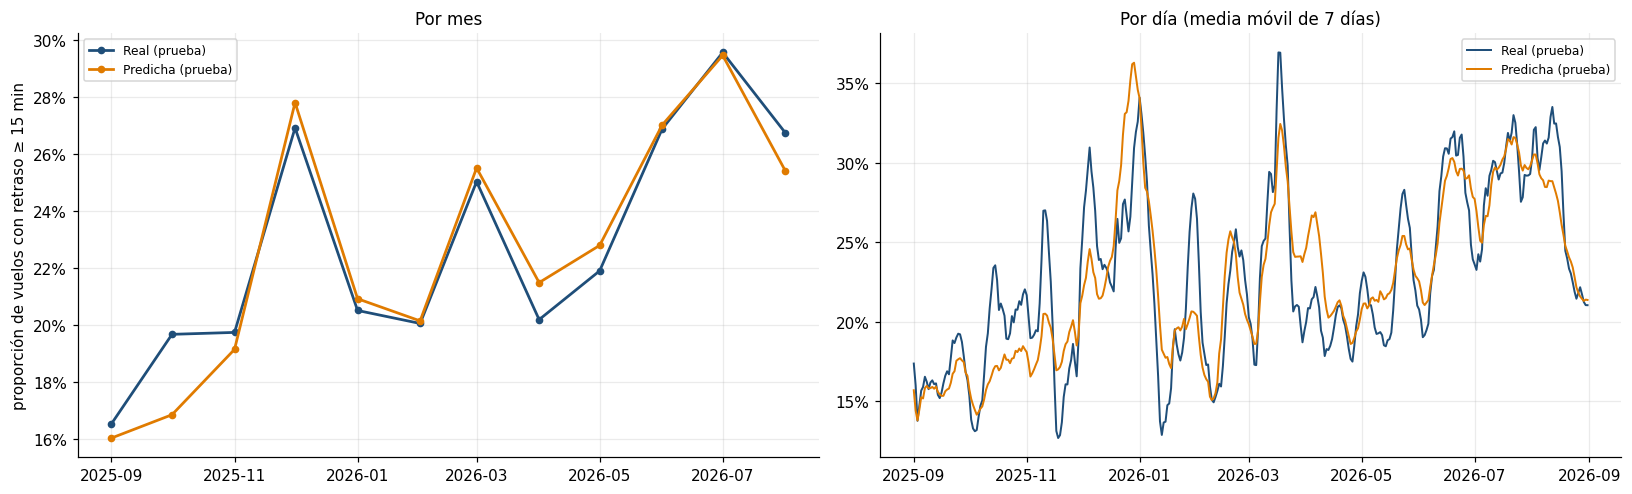

In [10]:
if RUN_GOLD_ANALYSIS:
    ts = T["timeseries"].copy(); ts["fecha"] = pd.to_datetime(ts.fecha); ts["mes"] = ts.fecha.dt.to_period("M").dt.to_timestamp()
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
    styles = {c: dict(ls=["-", "--", ":"][i % 3], marker="o" if i == 0 else "s") for i, c in enumerate(CONJ)}
    for c in CONJ:
        d = ts[ts.conjunto == c]
        m = d.groupby("mes").agg(v=("vuelos", "sum"), r=("retrasados", "sum"), p=("prob_suma", "sum"))
        ax[0].plot(m.index, m.r / m.v, color=COL_REAL, ms=4, lw=1.8, label=f"Real ({c})", **styles[c])
        ax[0].plot(m.index, m.p / m.v, color=COL_PRED, ms=4, lw=1.8, label=f"Predicha ({c})", **styles[c])
        dd = d.sort_values("fecha").set_index("fecha")
        roll = dd[["vuelos", "retrasados", "prob_suma"]].rolling("7D").sum()
        ax[1].plot(roll.index, roll.retrasados / roll.vuelos, color=COL_REAL, lw=1.3, ls=styles[c]["ls"], label=f"Real ({c})")
        ax[1].plot(roll.index, roll.prob_suma / roll.vuelos, color=COL_PRED, lw=1.3, ls=styles[c]["ls"], label=f"Predicha ({c})")
    ax[0].set(title="Por mes", ylabel="proporción de vuelos con retraso ≥ 15 min"); ax[1].set(title="Por día (media móvil de 7 días)")
    for a in ax: a.legend(fontsize=8); a.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    save_fig("01_serie_temporal")

## 3. Calibración y separación entre clases

- **Izquierda – calibración:** cada punto es un 1 % de los vuelos, agrupados por probabilidad predicha. Sobre la diagonal, la frecuencia observada coincide con lo que el modelo decía.
- **Derecha – separación:** distribución de la probabilidad predicha para vuelos que **sí** se retrasaron y los que **no**. Cuanto menos se solapan, mejor discrimina. La línea vertical es el umbral por costo.

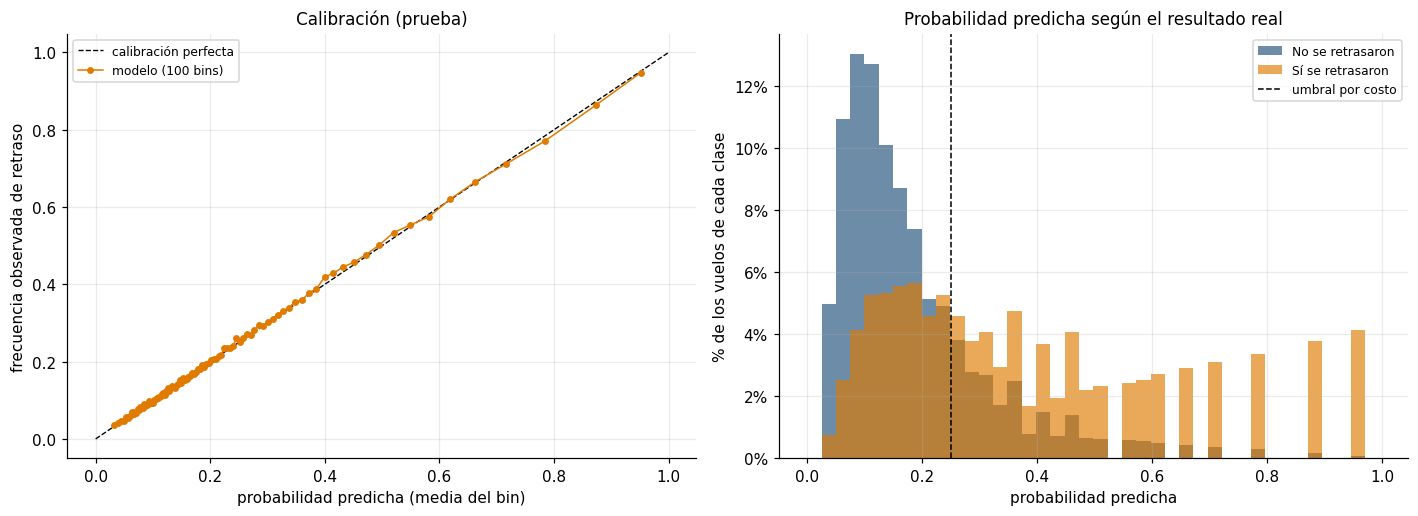

In [11]:
if RUN_GOLD_ANALYSIS:
    b = T["score_bins"].query("conjunto == @SET").sort_values("bin").copy()
    b["tasa"] = b.retrasados / b.vuelos
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    lim = max(b.p_media.max(), b.tasa.max()) * 1.05
    ax[0].plot([0, lim], [0, lim], "k--", lw=0.9, label="calibración perfecta")
    ax[0].plot(b.p_media, b.tasa, "o-", color=COL_PRED, ms=3.5, lw=1, label="modelo (100 bins)")
    ax[0].set(title=f"Calibración ({SET})", xlabel="probabilidad predicha (media del bin)", ylabel="frecuencia observada de retraso")
    ax[0].legend(fontsize=8)

    edges = np.linspace(0, b.p_max.max(), 41)
    pos_w = b.retrasados / b.retrasados.sum(); neg_w = (b.vuelos - b.retrasados) / (b.vuelos - b.retrasados).sum()
    ax[1].hist(b.p_media, bins=edges, weights=neg_w, alpha=0.65, color=COL_REAL, label="No se retrasaron")
    ax[1].hist(b.p_media, bins=edges, weights=pos_w, alpha=0.65, color=COL_PRED, label="Sí se retrasaron")
    ax[1].axvline(meta["conjuntos"][SET]["umbral"], color="k", ls="--", lw=1, label="umbral por costo")
    ax[1].set(title="Probabilidad predicha según el resultado real", xlabel="probabilidad predicha", ylabel="% de los vuelos de cada clase")
    ax[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax[1].legend(fontsize=8)
    save_fig("02_calibracion_separacion")

## 4. ROC, Precisión–Recall y ganancia acumulada

La **ganancia** responde la pregunta operativa: *si solo puedo vigilar el X % de vuelos con mayor riesgo, ¿qué fracción de los retrasos reales capturo?* La diagonal es vigilar al azar.

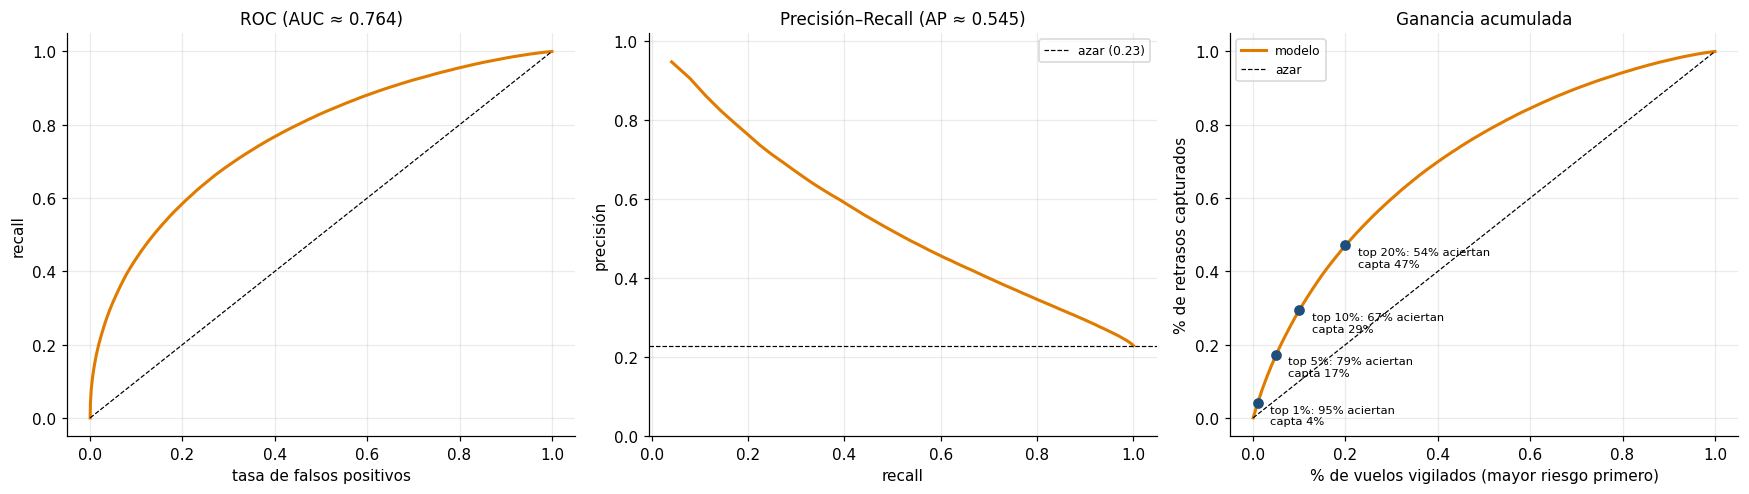

In [12]:
if RUN_GOLD_ANALYSIS:
    o = b.sort_values("p_media", ascending=False)
    N, P = o.vuelos.sum(), o.retrasados.sum()
    tp = np.r_[0, o.retrasados.cumsum()]; fp = np.r_[0, (o.vuelos - o.retrasados).cumsum()]
    tpr, fpr, prec, share = tp / P, fp / (N - P), np.r_[1, tp[1:] / (tp[1:] + fp[1:])], (tp + fp) / N
    auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2); ap = np.sum(np.diff(tpr) * prec[1:])

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
    ax[0].plot(fpr, tpr, color=COL_PRED, lw=2); ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    ax[0].set(title=f"ROC (AUC ≈ {auc:.3f})", xlabel="tasa de falsos positivos", ylabel="recall")
    ax[1].plot(tpr[1:], prec[1:], color=COL_PRED, lw=2); ax[1].axhline(P / N, color="k", ls="--", lw=0.8, label=f"azar ({P / N:.2f})")
    ax[1].set(title=f"Precisión–Recall (AP ≈ {ap:.3f})", xlabel="recall", ylabel="precisión", ylim=(0, 1.02)); ax[1].legend(fontsize=8)
    ax[2].plot(share, tpr, color=COL_PRED, lw=2, label="modelo"); ax[2].plot([0, 1], [0, 1], "k--", lw=0.8, label="azar")
    for k in (0.01, 0.05, 0.10, 0.20):
        i = np.searchsorted(share, k)
        ax[2].plot(share[i], tpr[i], "o", color=COL_REAL); ax[2].annotate(f"top {k:.0%}: {prec[i]:.0%} aciertan\ncapta {tpr[i]:.0%}", (share[i], tpr[i]),
                                                                         textcoords="offset points", xytext=(8, -14), fontsize=7.5)
    ax[2].set(title="Ganancia acumulada", xlabel="% de vuelos vigilados (mayor riesgo primero)", ylabel="% de retrasos capturados"); ax[2].legend(fontsize=8)
    save_fig("03_roc_pr_ganancia")

## 5. Real vs predicha por subgrupo

Cada gráfica tiene dos paneles: a la izquierda, tasa real y predicha; a la derecha, la **brecha en puntos porcentuales** (predicha − real). Barras a la derecha del cero = el modelo sobreestima el retraso; a la izquierda = lo subestima.

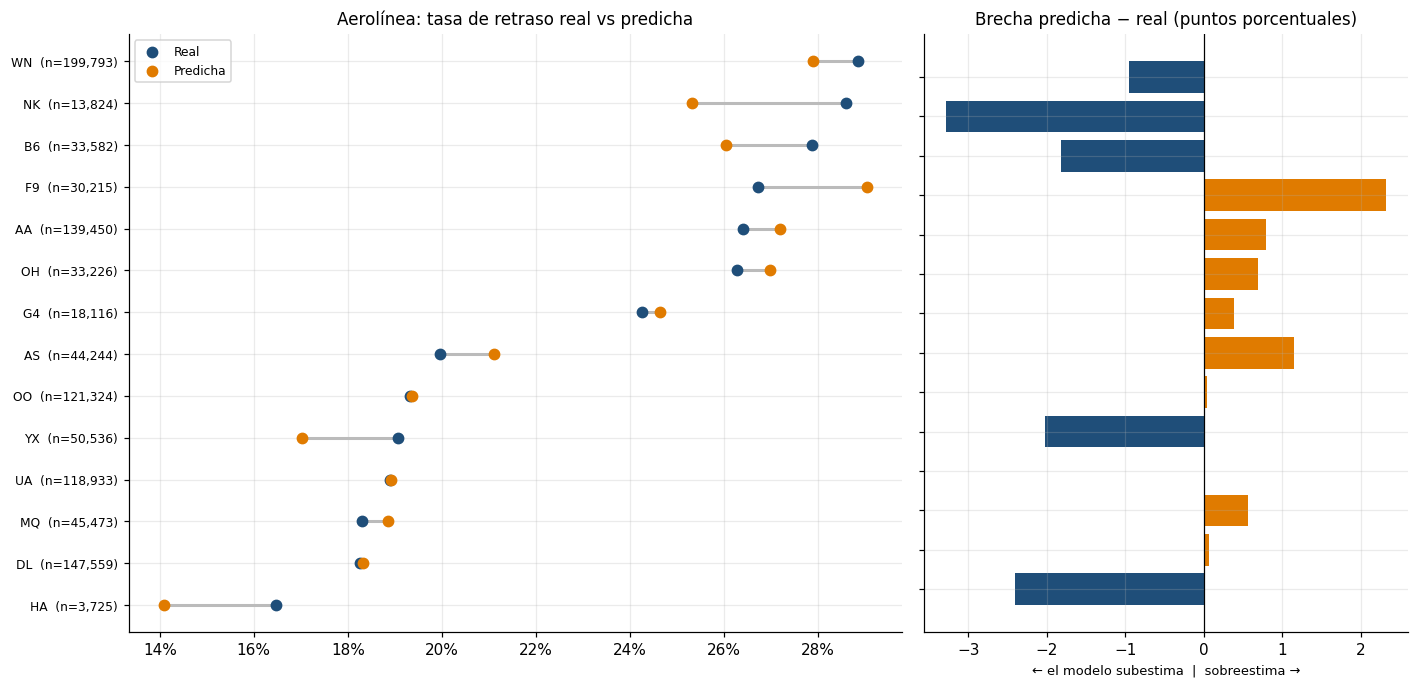

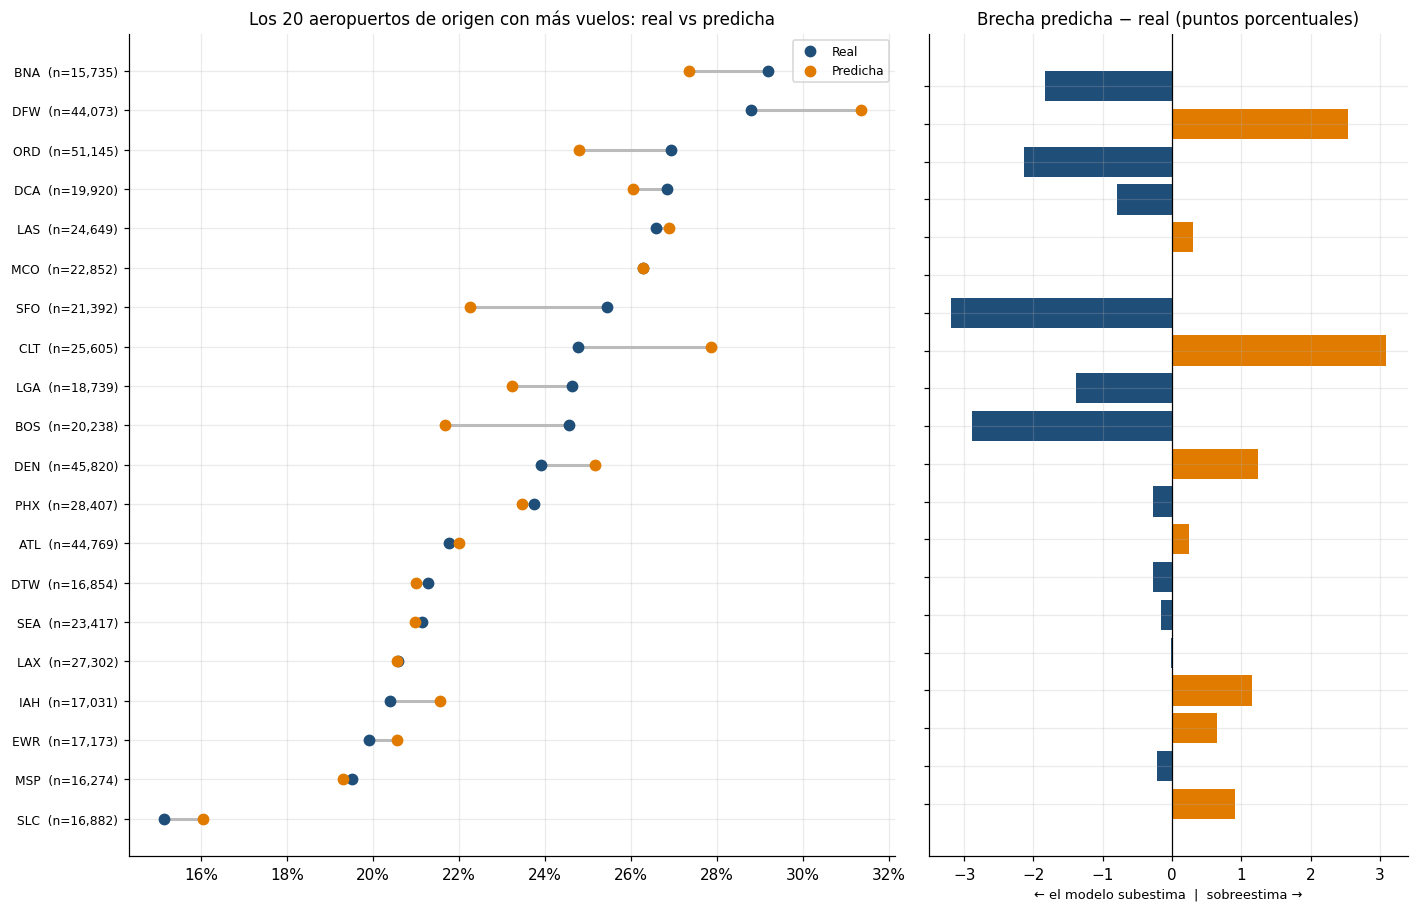

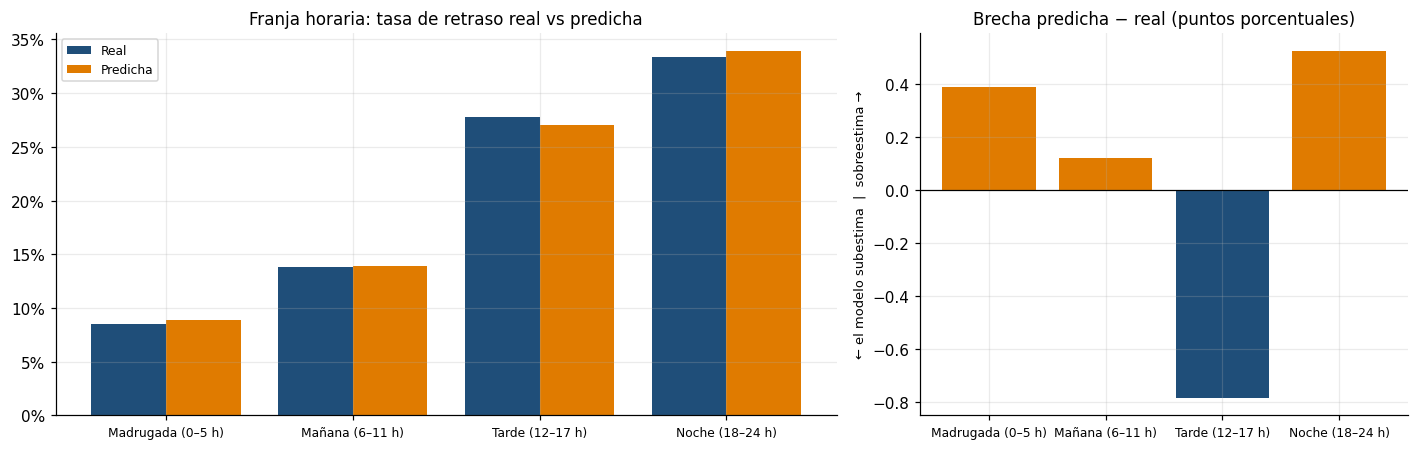

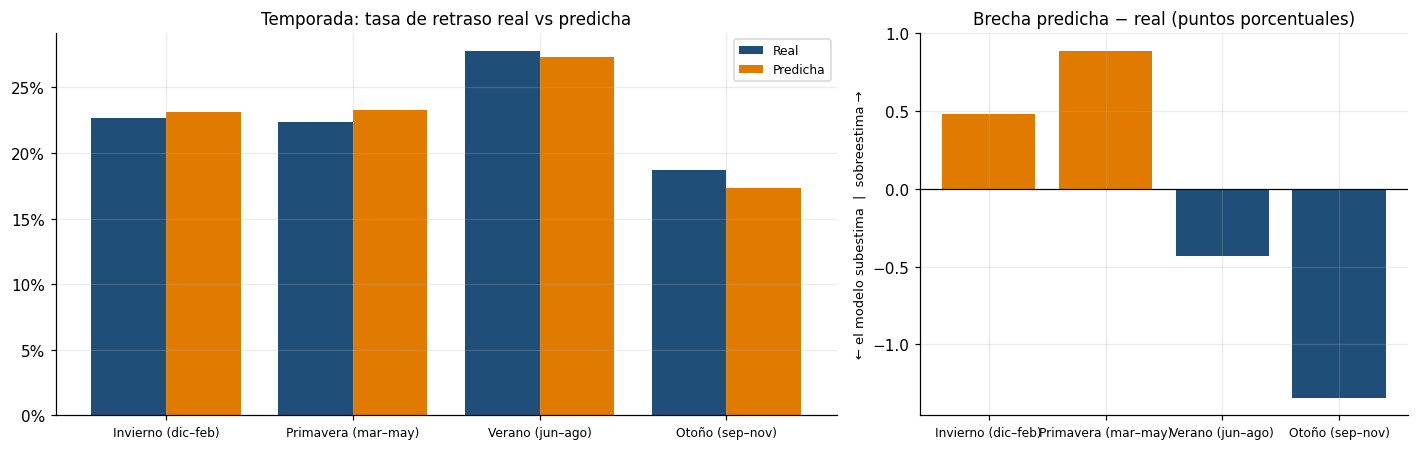

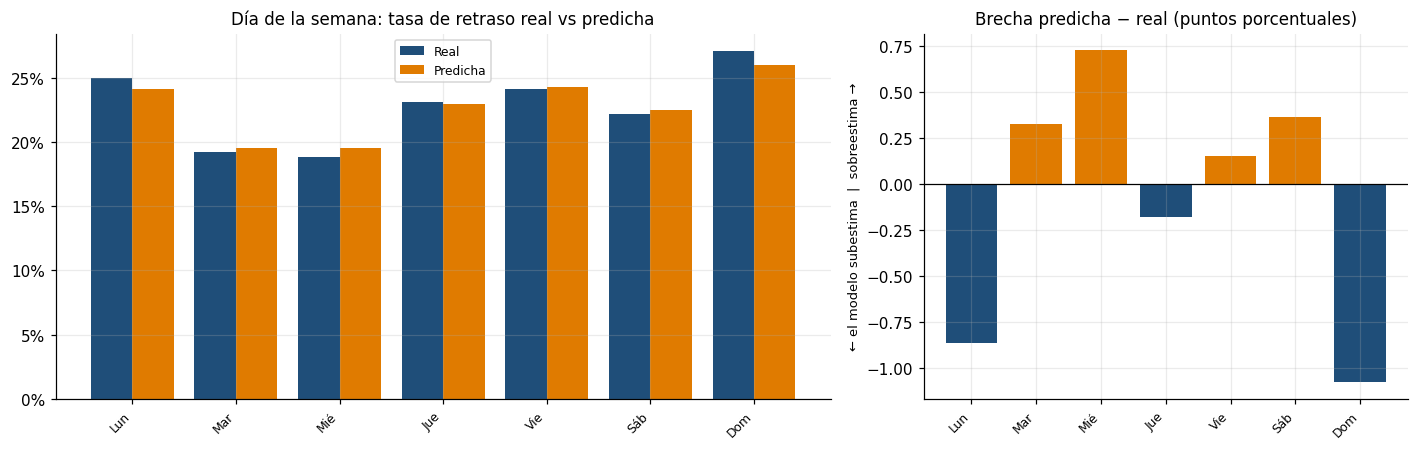

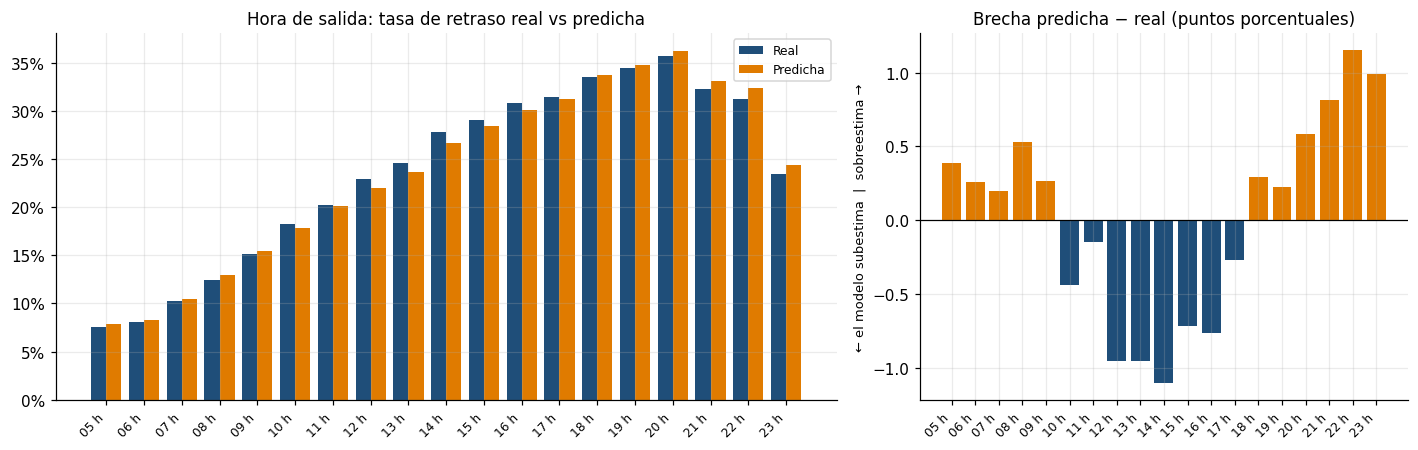

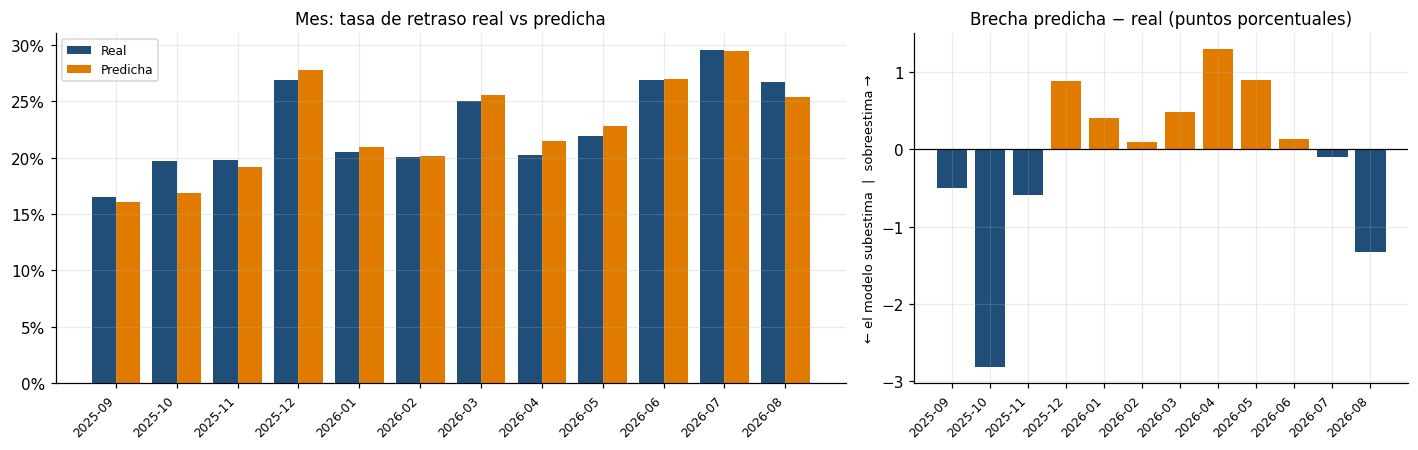

In [13]:
if RUN_GOLD_ANALYSIS:
    G = T["group_metrics"].query("conjunto == @SET and dimension != 'Global' and vuelos >= @MIN_FLIGHTS").copy()
    G["brecha_pp"] = (G.prob_media - G.tasa_real) * 100

    def compare(dim, kind, top=None, title=None):
        d = G[G.dimension == dim].sort_values("orden")
        if top: d = d.nsmallest(top, "orden")
        if kind == "dumbbell":
            d = d.sort_values("tasa_real")
        y = np.arange(len(d))
        fig, ax = plt.subplots(1, 2, figsize=(13, max(3.2, 0.34 * len(d) + 1.6)) if kind == "dumbbell" else (13, 4.2),
                               gridspec_kw={"width_ratios": [1.6, 1]})
        if kind == "dumbbell":
            ax[0].hlines(y, d.tasa_real, d.prob_media, color="#bbbbbb", lw=2)
            ax[0].scatter(d.tasa_real, y, color=COL_REAL, s=45, zorder=3, label="Real")
            ax[0].scatter(d.prob_media, y, color=COL_PRED, s=45, zorder=3, label="Predicha")
            ax[0].set_yticks(y, [f"{g}  (n={n:,})" for g, n in zip(d.grupo, d.vuelos)], fontsize=8)
            ax[1].barh(y, d.brecha_pp, color=np.where(d.brecha_pp > 0, COL_PRED, COL_REAL)); ax[1].set_yticks(y, [""] * len(d))
        else:
            x = np.arange(len(d)); w = 0.4
            ax[0].bar(x - w / 2, d.tasa_real, w, color=COL_REAL, label="Real"); ax[0].bar(x + w / 2, d.prob_media, w, color=COL_PRED, label="Predicha")
            ax[0].set_xticks(x, d.grupo, rotation=45 if len(d) > 6 else 0, ha="right" if len(d) > 6 else "center", fontsize=8)
            ax[1].bar(x, d.brecha_pp, color=np.where(d.brecha_pp > 0, COL_PRED, COL_REAL)); ax[1].set_xticks(x, d.grupo, rotation=45 if len(d) > 6 else 0,
                                                                                                        ha="right" if len(d) > 6 else "center", fontsize=8)
        ax[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}") if kind == "dumbbell" else ax[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
        ax[0].set_title(title or f"{dim}: tasa de retraso real vs predicha"); ax[0].legend(fontsize=8)
        ax[1].axvline(0, color="k", lw=0.8) if kind == "dumbbell" else ax[1].axhline(0, color="k", lw=0.8)
        ax[1].set_title("Brecha predicha − real (puntos porcentuales)")
        (ax[1].set_xlabel if kind == "dumbbell" else ax[1].set_ylabel)("← el modelo subestima  |  sobreestima →", fontsize=8.5)
        save_fig(f"04_{dim.lower().replace(' ', '_').replace('é', 'e').replace('í', 'i').replace('ó', 'o')}")

    compare("Aerolínea", "dumbbell")
    compare("Aeropuerto de origen", "dumbbell", top=TOP_AIRPORTS, title=f"Los {TOP_AIRPORTS} aeropuertos de origen con más vuelos: real vs predicha")
    for dim in ["Franja horaria", "Temporada", "Día de la semana", "Hora de salida", "Mes"]:
        compare(dim, "bars")

## 6. Mapa de calor: hora de salida × día de la semana

Muestra **dónde** está la brecha. Celdas con pocos vuelos se dejan en blanco.

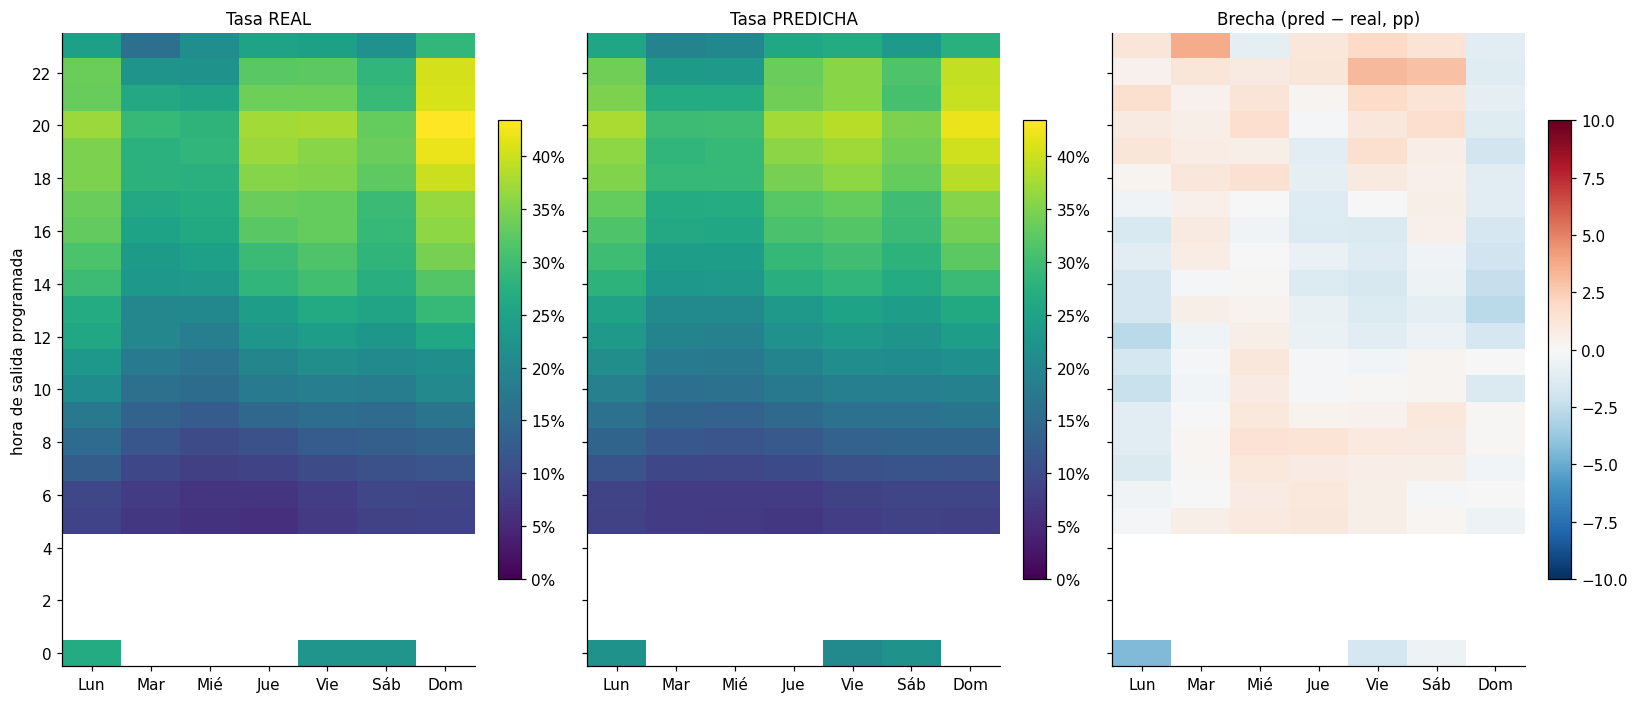

In [14]:
if RUN_GOLD_ANALYSIS:
    h = T["heat_hora_dia"].query("conjunto == @SET").copy()
    h["real"] = h.retrasados / h.vuelos; h["pred"] = h.prob_suma / h.vuelos; h["dif"] = (h.pred - h.real) * 100
    mask = h.vuelos < 200
    for c in ("real", "pred", "dif"):
        h.loc[mask, c] = np.nan
    piv = {c: h.pivot(index="hora", columns="dia_semana", values=c) for c in ("real", "pred", "dif")}
    dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
    vmax = np.nanmax([piv["real"].values, piv["pred"].values])
    fig, ax = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
    for a, (c, ttl, cmap, lim) in zip(ax, [("real", "Tasa REAL", "viridis", (0, vmax)), ("pred", "Tasa PREDICHA", "viridis", (0, vmax)),
                                           ("dif", "Brecha (pred − real, pp)", "RdBu_r", (-10, 10))]):
        im = a.imshow(piv[c].values, aspect="auto", cmap=cmap, vmin=lim[0], vmax=lim[1], origin="lower")
        a.set_xticks(range(len(dias)), [dias[int(i) - 1] for i in piv[c].columns]); a.set_title(ttl); a.grid(False)
        plt.colorbar(im, ax=a, fraction=0.05, format=(lambda v, _: f"{v:.0%}") if c != "dif" else None)
    ax[0].set_yticks(range(len(piv["real"].index))[::2], piv["real"].index[::2]); ax[0].set_ylabel("hora de salida programada")
    save_fig("05_mapa_calor_hora_dia")

## 7. Matriz de confusión al umbral por costo

Global y por franja horaria. Cada fila suma 100 %: la fila "Real retraso" muestra qué fracción de los retrasos se detectó (recall) y la fila "Real puntual", cuántos vuelos puntuales se marcaron en falso.

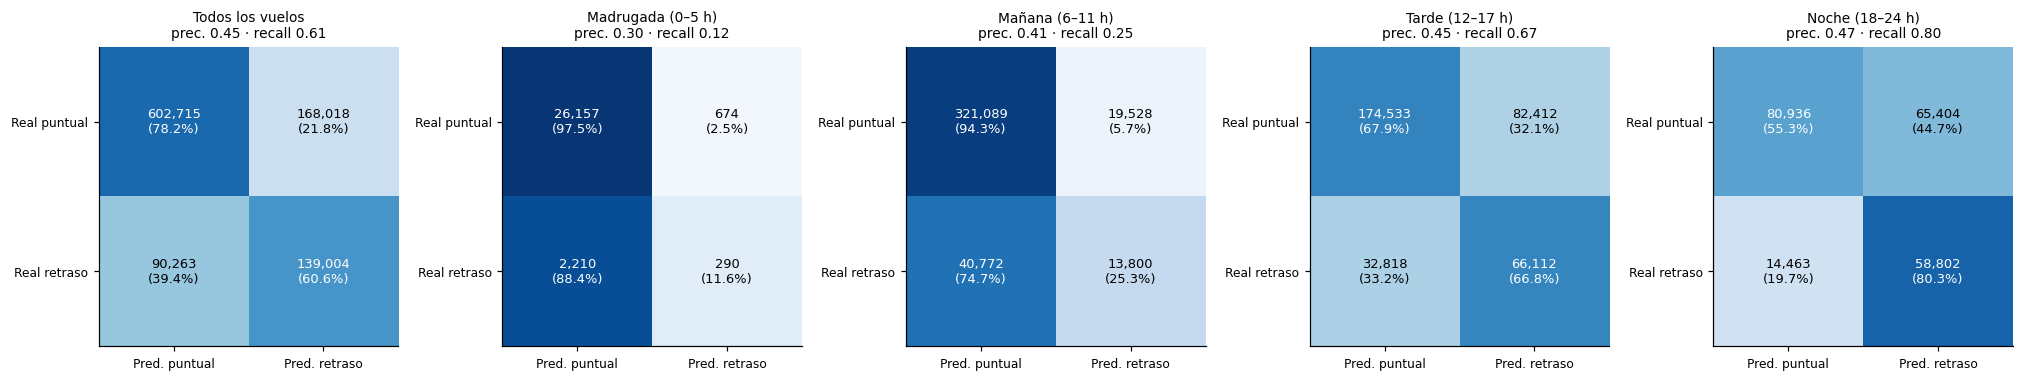

In [15]:
if RUN_GOLD_ANALYSIS:
    cm_rows = pd.concat([T["group_metrics"].query("conjunto == @SET and dimension == 'Global'"),
                         T["group_metrics"].query("conjunto == @SET and dimension == 'Franja horaria'").sort_values("orden")])
    fig, axes = plt.subplots(1, len(cm_rows), figsize=(3.7 * len(cm_rows), 3.9))
    for a, (_, r) in zip(np.atleast_1d(axes), cm_rows.iterrows()):
        cm = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=float); pct = cm / cm.sum(axis=1, keepdims=True)
        a.imshow(pct, cmap="Blues", vmin=0, vmax=1); a.grid(False)
        for i in range(2):
            for j in range(2):
                a.text(j, i, f"{int(cm[i, j]):,}\n({pct[i, j]:.1%})", ha="center", va="center", fontsize=8.5, color="white" if pct[i, j] > 0.5 else "black")
        a.set_xticks([0, 1], ["Pred. puntual", "Pred. retraso"], fontsize=8); a.set_yticks([0, 1], ["Real puntual", "Real retraso"], fontsize=8)
        a.set_title(f"{r.grupo}\nprec. {r.precision:.2f} · recall {r.recall:.2f}", fontsize=9)
    save_fig("06_matrices_confusion")

## 8. Sensibilidad al costo del error

La propuesta fija un costo (falsa alarma : retraso no detectado = 1 : 3) que es un **supuesto**. Aquí se ve cómo cambia la decisión si la razón real fuera otra: el umbral óptimo, qué porcentaje de vuelos se marcaría y qué precisión y recall resultarían. El costo está en unidades relativas (una falsa alarma = 1), **no es dinero**.

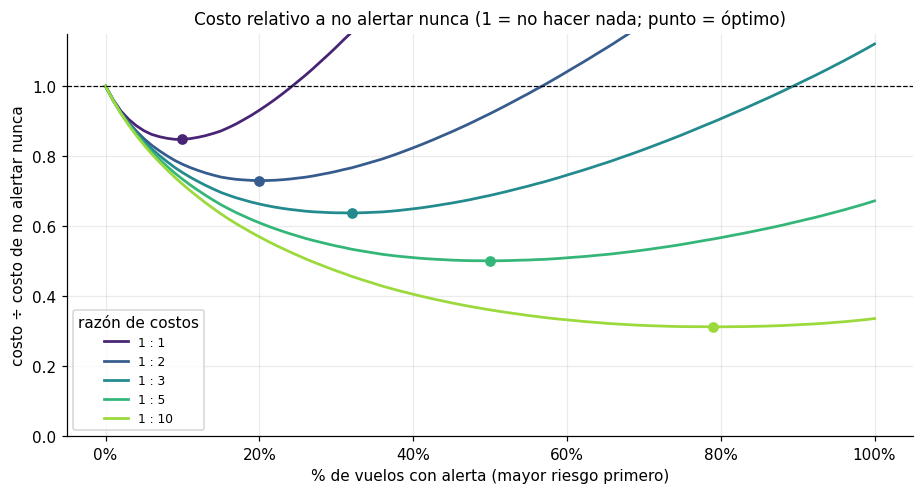

,umbral óptimo ≈,% de vuelos con alerta,precisión,recall,costo por 1000 vuelos (u. relativas),costo vs no alertar nunca
razón (falsa alarma : retraso perdido),,,,,,
1 : 1,0.4826,0.1000,0.6742,0.2941,194.4310,0.8481
1 : 2,0.3324,0.2000,0.5394,0.4706,334.8820,0.7303
1 : 3,0.2425,0.3200,0.4448,0.6208,438.4930,0.6375
1 : 5,0.1665,0.5000,0.3573,0.7793,574.3330,0.5010
1 : 10,0.0923,0.7900,0.2723,0.9383,716.3170,0.3124


In [16]:
if RUN_GOLD_ANALYSIS:
    RATIOS = [1, 2, 3, 5, 10]
    pe = b.sort_values("p_media", ascending=False)
    Np, Pp = pe.vuelos.sum(), pe.retrasados.sum()
    tp_k = np.r_[0, pe.retrasados.cumsum().values]; fp_k = np.r_[0, (pe.vuelos - pe.retrasados).cumsum().values]
    fn_k = Pp - tp_k; share_k = (tp_k + fp_k) / Np
    thr_k = np.r_[1.0, pe.p_min.values]                     # umbral aproximado si se alertan los k bins de mayor riesgo
    rows = []
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    for r, col in zip(RATIOS, plt.cm.viridis(np.linspace(0.1, 0.85, len(RATIOS)))):
        cost = (fp_k + r * fn_k) / Np * 1000
        never = r * Pp / Np * 1000                              # costo de no alertar nunca (se pierden todos los retrasos)
        k = int(np.argmin(cost))
        ax.plot(share_k, cost / never, color=col, lw=1.8, label=f"1 : {r}"); ax.plot(share_k[k], cost[k] / never, "o", color=col)
        rows.append({"razón (falsa alarma : retraso perdido)": f"1 : {r}", "umbral óptimo ≈": thr_k[k], "% de vuelos con alerta": share_k[k],
                     "precisión": tp_k[k] / max(tp_k[k] + fp_k[k], 1), "recall": tp_k[k] / Pp,
                     "costo por 1000 vuelos (u. relativas)": cost[k], "costo vs no alertar nunca": cost[k] / never})
    ax.axhline(1, color="k", ls="--", lw=0.8)
    ax.set(title="Costo relativo a no alertar nunca (1 = no hacer nada; punto = óptimo)", xlabel="% de vuelos con alerta (mayor riesgo primero)", ylabel="costo ÷ costo de no alertar nunca")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylim(0, 1.15); ax.legend(title="razón de costos", fontsize=8)
    save_fig("07_sensibilidad_costo")
    display(pd.DataFrame(rows).set_index("razón (falsa alarma : retraso perdido)"))

## 9. Mayores brechas entre predicción y realidad

Subgrupos (con al menos `MIN_FLIGHTS` vuelos) donde el promedio predicho más se aleja de la tasa real, y subgrupos donde el modelo ordena peor los vuelos (ROC-AUC más bajo). Un sesgo localizado se corrige con variables o calibración por grupo, no con hiperparámetros.

In [17]:
if RUN_GOLD_ANALYSIS:
    cols = ["dimension", "grupo", "vuelos", "tasa_real", "prob_media", "brecha_pp", "sesgo", "roc_auc", "pr_auc"]
    print("Mayor brecha absoluta (predicha − real):")
    display(G.loc[G.brecha_pp.abs().sort_values(ascending=False).index[:10], cols].reset_index(drop=True))
    print("Menor capacidad de ordenar (ROC-AUC más bajo):")
    display(G.sort_values("roc_auc").head(10)[cols].reset_index(drop=True))

Mayor brecha absoluta (predicha − real):


,dimension,grupo,vuelos,tasa_real,prob_media,brecha_pp,sesgo,roc_auc,pr_auc
0,Aeropuerto de origen,KOA,2305,0.1262,0.1677,4.1412,1.3280,0.7188,0.2587
1,Aeropuerto de origen,LIH,2307,0.1374,0.1737,3.6317,1.2643,0.7476,0.3260
2,Aerolínea,NK,13824,0.2860,0.2532,-3.2809,0.8853,0.7475,0.5873
3,Aeropuerto de origen,SFO,21392,0.2544,0.2225,-3.1950,0.8744,0.7735,0.5724
4,Aeropuerto de origen,CLT,25605,0.2478,0.2787,3.0892,1.1247,0.7852,0.6195
5,Aeropuerto de origen,BOS,20238,0.2456,0.2167,-2.8892,0.8824,0.7673,0.5753
6,Aeropuerto de origen,OGG,3589,0.1544,0.1830,2.8682,1.1858,0.7104,0.3310
7,Mes,2025-10,87101,0.1967,0.1685,-2.8190,0.8567,0.7646,0.5151
8,Aeropuerto de origen,SAN,14258,0.2711,0.2436,-2.7492,0.8986,0.7810,0.6091
9,Aeropuerto de origen,BWI,13472,0.2743,0.3016,2.7292,1.0995,0.7701,0.6044


Menor capacidad de ordenar (ROC-AUC más bajo):


,dimension,grupo,vuelos,tasa_real,prob_media,brecha_pp,sesgo,roc_auc,pr_auc
0,Hora de salida,06 h,68545,0.0805,0.0831,0.2618,1.0325,0.6254,0.1441
1,Hora de salida,05 h,27139,0.0752,0.0790,0.3872,1.0515,0.6289,0.1275
2,Hora de salida,07 h,74660,0.1022,0.1042,0.1982,1.0194,0.6504,0.2314
3,Franja horaria,Madrugada (0–5 h),29331,0.0852,0.0891,0.3877,1.0455,0.6620,0.1789
4,Hora de salida,08 h,69398,0.1243,0.1296,0.5306,1.0427,0.6678,0.3175
5,Aeropuerto de origen,XNA,2063,0.1745,0.1905,1.5974,1.0915,0.6720,0.3694
6,Hora de salida,09 h,57033,0.1518,0.1545,0.2646,1.0174,0.6829,0.3710
7,Hora de salida,10 h,63808,0.1826,0.1782,-0.4366,0.9761,0.6947,0.4134
8,Franja horaria,Mañana (6–11 h),395189,0.1381,0.1393,0.1206,1.0087,0.6982,0.3547
9,Hora de salida,11 h,61745,0.2022,0.2008,-0.1481,0.9927,0.6998,0.4443


## Nota sobre los datos posteriores a 2026-08

El conjunto `prueba` ya tiene resultados reales, así que no hace falta nada más para este análisis. Si en la capa oro existe un conjunto `prospectivo` (meses que ningún paso del proyecto vio, ni para entrenar ni para elegir modelo), las secciones 1 y 2 lo muestran junto a la prueba, y cambiando `SET = "prospectivo"` arriba todas las demás gráficas se calculan sobre él. Es la comparación más honesta del modelo.

## III. Publicación opcional de figuras Gold en S3

Solo después de ejecutar la sección II con Gold definitivo. Esta publicación no vuelve a entrenar ni regenera las tablas.

In [21]:
if RUN_GOLD_ANALYSIS:
    SUBIR_FIGURAS_GOLD = True
    if SUBIR_FIGURAS_GOLD:
        import boto3
        cliente = boto3.Session(region_name="us-east-1").client("s3")
        version = meta["model_version"]
        for archivo in sorted(FIG_DIR.glob("*.png")):
            key = f"modeling/analysis/gold_figures/{version}/{archivo.name}"
            cliente.upload_file(str(archivo), BUCKET, key)
            print("Subido:", f"s3://{BUCKET}/{key}")
        print("✔ Figuras Gold respaldadas")
    else:
        print("Subida de figuras Gold desactivada (requiere terminar sección II).")

Subido: s3://bts-flights-analysis/modeling/analysis/gold_figures/lgbm-f64-seed42-h240-20261122T031926Z-trial-038/calibration.png
Subido: s3://bts-flights-analysis/modeling/analysis/gold_figures/lgbm-f64-seed42-h240-20261122T031926Z-trial-038/calidad_vs_tiempo.png
Subido: s3://bts-flights-analysis/modeling/analysis/gold_figures/lgbm-f64-seed42-h240-20261122T031926Z-trial-038/confusion_matrices.png
Subido: s3://bts-flights-analysis/modeling/analysis/gold_figures/lgbm-f64-seed42-h240-20261122T031926Z-trial-038/feature_importance.png
Subido: s3://bts-flights-analysis/modeling/analysis/gold_figures/lgbm-f64-seed42-h240-20261122T031926Z-trial-038/roc_pr_curves.png
Subido: s3://bts-flights-analysis/modeling/analysis/gold_figures/lgbm-f64-seed42-h240-20261122T031926Z-trial-038/subgrupos_aerolínea.png
Subido: s3://bts-flights-analysis/modeling/analysis/gold_figures/lgbm-f64-seed42-h240-20261122T031926Z-trial-038/subgrupos_aeropuerto_de_origen.png
Subido: s3://bts-flights-analysis/modeling/analy